# DLENT-RT — Main algorithm analysis (theory model)

One configuration only: `BASE = apply_overrides(cfg, {"bid.strategy": "lognormal", "bid.sigma": 0.3})` on top of
`configs/default.yaml`, with the default normalization (`quantile_linear`, q = 0.90, no common divisor,
norm_ref = (1, 1, 1), s_C frozen in Phase 0). Reward in dollars, unbounded.
Theoretical setting: the true duration of an admitted job is known at arrival (`model.kind = "theory"`).

Notebook-only knob: `capacity_scale` multiplies the initial cluster capacity c_i (CPU and RAM) **before Phase 0**.
It is an override inside this notebook, not a change of the default. Sweep: capacity_scale in {0.5, 1.0, 1.5, 2.0, 3.0};
every section below is for the baseline 1.0, the sweep is the compact table + occupancy figure of Section 6.

Sections: 0. Setup &middot; 1. Distributions (C.1) &middot; 2. Per-phase margin (C.2) &middot;
3. Results per phase (C.3) &middot; 4. Accuracy per phase (C.4) &middot; 5. Baselines and regret (C.5) &middot;
6. capacity_scale sweep &middot; 7. Anomalies.

Rebuild/execute: `python notebooks/src/build.py 03_main_algorithm_analysis --execute`.
Data: real trace only, `data/batch_may2019_30k.csv` + `data/grid_data_may_2019.csv` (no synthetic data).
Fewer scales for a quick run: `DLENT_SCALES=1.0`.

## Section 0: Setup and configuration

In [1]:
import os, sys, time, warnings, dataclasses
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import milp, linprog, LinearConstraint, Bounds
from scipy.stats import lognorm
from IPython.display import display
warnings.simplefilter("ignore")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlent_rt").is_dir())
sys.path.insert(0, str(ROOT))

from dlent_rt.config import default_config
from dlent_rt.data import load_dataset
from dlent_rt.phase0 import (run_phase0, assign_type_ids, type_arrays, scalarized_reward,
                             _weighted_quantile)
from dlent_rt.models.theory import TheoryModel
from dlent_rt.models.core.occupancy import Occupancy
from dlent_rt.models.core.reinit import build_window_state
from dlent_rt.models.core.error_params import make_error_params

plt.rcParams["figure.figsize"] = (13, 3.6)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

# palette (notebook 01 conventions: named matplotlib colours)
C_SW, C_PI, C_C, C_BID = "steelblue", "darkorange", "gray", "steelblue"
C_CPU, C_RAM = "steelblue", "darkorange"
DEC_ORDER = ["accepted", "oracle reject", "thinning reject", "physical reject", "IR reject"]
DEC_STYLE = {"accepted": ("seagreen", "o"), "oracle reject": ("gray", "x"),
             "thinning reject": ("darkorange", "v"), "physical reject": ("indianred", "s"),
             "IR reject": ("purple", "D")}

In [ ]:
def _replace_path(obj, path, value):
    if len(path) == 1:
        return dataclasses.replace(obj, **{path[0]: value})
    head, rest = path[0], path[1:]
    return dataclasses.replace(obj, **{head: _replace_path(getattr(obj, head), rest, value)})

def apply_overrides(cfg, overrides: dict):
    """Apply {'a.b.c': value, ...} on top of cfg via recursive dataclasses.replace."""
    for dotted_key, value in overrides.items():
        cfg = _replace_path(cfg, dotted_key.split("."), value)
    return cfg

# Real trace only (no synthetic fallback): the full 30k batch trace and the May-2019 grid data.
BATCH_CSV = ROOT / "data" / "batch_may2019_30k.csv"
GRID_CSV = ROOT / "data" / "grid_data_may_2019.csv"
for _p in (BATCH_CSV, GRID_CSV):
    if not _p.is_file():
        raise FileNotFoundError(f"required input not found: {_p}")

cfg = apply_overrides(default_config(), {"data.batch_csv": str(BATCH_CSV), "data.grid_csv": str(GRID_CSV)})
BASE = apply_overrides(cfg, {"bid.strategy": "lognormal", "bid.sigma": 0.3})
# Notebook-only override (week-29 report): configs/default.yaml now has data.n0 = 24,000 (|stream| = 133);
# the analysis is run with the H/stream split it was designed for, n0 = 20,000 (|stream| = 4,133).
N0_OVERRIDE = 10000
if BASE.data.n0 != N0_OVERRIDE:
    print(f"OVERRIDE: data.n0 {BASE.data.n0:,} (configs/default.yaml) -> {N0_OVERRIDE:,} (this notebook only)")
    BASE = apply_overrides(BASE, {"data.n0": N0_OVERRIDE})
BASE = BASE.validate()
print(f"batch trace: {BATCH_CSV}\ngrid data:   {GRID_CSV}")

CAPACITY_SCALES = [float(x) for x in os.environ.get("DLENT_SCALES", "0.5,1.0").split(",")]
BASELINE_SCALE = 1.0
assert BASELINE_SCALE in CAPACITY_SCALES
L1, L2, L3 = BASE.objective.lambda1, BASE.objective.lambda2, BASE.objective.lambda3
print(f"model={BASE.model.kind}  oracle={BASE.oracle.kind}  scalarization={BASE.scalarization.method}")
print(f"bid: strategy={BASE.bid.strategy} sigma={BASE.bid.sigma} u0={BASE.bid.base_utility_u0} "
      f"mode={BASE.bid.base_utility_mode}")
print(f"normalization: {BASE.normalization.strategy}  q={BASE.normalization.quantile}")
print(f"lambda = ({L1}, {L2}, {L3})   k_star={BASE.grid.k_star}  hw profiles={BASE.hardware.n_profiles}")
print(f"constants: gamma_override={BASE.constants.gamma_override}  xi_override={BASE.constants.xi_override}  "
      f"delta={BASE.confidence.delta} (1/T^{BASE.confidence.delta_power} if None)")
print(f"capacity: mode={BASE.capacity.mode} fraction={BASE.capacity.fraction} "
      f"q={BASE.capacity.concurrency_quantile}   capacity_scale sweep = {CAPACITY_SCALES}")

batch trace: /Users/francescodangolo/Projects/dlent_rt/data/batch_may2019_30k.csv
grid data:   /Users/francescodangolo/Projects/dlent_rt/data/grid_data_may_2019.csv
model=theory  oracle=frozen  scalarization=linear
bid: strategy=lognormal sigma=0.3 u0=23.926 mode=log
normalization: quantile_linear  q=0.9
lambda = (1.0, 1.0, 1.0)   k_star=128  hw profiles=32
constants: gamma_override=1.0  xi_override=0.001  delta=None (1/T^3 if None)
capacity: mode=from_amax fraction=0.4 q=0.8   capacity_scale sweep = [0.5, 1.0, 1.5, 2.0, 3.0]


In [3]:
t_load = time.time()
ds0 = load_dataset(BASE)
print(f"seeds: run.seed={BASE.run.seed} (Phase-0 bids)  stream bids={BASE.run.seed + BASE.online.bid_seed_offset}  "
      f"thinning U(t)={BASE.run.seed + BASE.online.thinning_seed_offset}")
print(f"|H| = {ds0.H.n:,}  (config data.n0 = {BASE.data.n0:,}: "
      f"{'matches' if ds0.H.n == BASE.data.n0 else 'DIFFERS from the config value'})")
print(f"|stream| = {ds0.stream.n:,}   T = {ds0.T:,} ticks of {BASE.time.tick_seconds:g} s   "
      f"d_max = {ds0.d_max_steps:,} ticks   H spans {ds0.H_span_steps:,} ticks")
print(f"capacity c (scale 1.0) = {np.round(ds0.capacity, 5)}   a_max (stream) = {np.round(ds0.a_max, 5)}   "
      f"xi_data = max a_max/c = {ds0.xi:.4f}")
print(f"loaded in {time.time() - t_load:.1f} s")

seeds: run.seed=42 (Phase-0 bids)  stream bids=43  thinning U(t)=44
|H| = 10,000  (config data.n0 = 10,000: matches)
|stream| = 15,308   T = 1,432,910 ticks of 1 s   d_max = 14,304 ticks   H spans 1,245,441 ticks
capacity c (scale 1.0) = [3.94545 2.5551 ]   a_max (stream) = [1.97273 1.27755]   xi_data = max a_max/c = 0.5000
loaded in 1.0 s


### 0.1 What `capacity_scale` changes

`capacity_scale` multiplies c before Phase 0, so it changes:
* **ξ** — the data value ξ_data = max_i a_max,i / c_i scales as 1/scale. The value *used* by the loop is the forced
  `constants.xi_override` (unchanged by the scale); with a forced ξ, Test 1 uses a_max,eff = ξ·c, which scales with c.
* **the thinning cap** — p_U(t) = (1 − ξ) / (1 + ε_D + η(W_prev) + η(t − τ_prev)) with η(n) = γ / (c_min √n);
  c_min scales, so η shrinks and p_U rises toward its cap (1 − ξ)/(1 + ε_D).
* **the physical gate** — admission requires U + A_j ≤ c; jobs with A_j > c can never be admitted.
* the LP-RS (τ, λ̂) and the Test 2/3 radii through c_min (ε_A', η).

In [4]:
def scaled_dataset(ds, s):
    c = np.asarray(ds.capacity, float) * s
    return dataclasses.replace(ds, capacity=c, xi=float(np.max(np.asarray(ds.a_max) / c)))

class RecordingModel(TheoryModel):
    """TheoryModel that also keeps the PhaseState used in each phase (analysis only, no logic change)."""
    def run(self):
        self.states = []
        return super().run()

    def _new_phase(self, state, tau_prev, W_prev):
        self.states.append(state)
        super()._new_phase(state, tau_prev, W_prev)

rows = []
for s in CAPACITY_SCALES:
    ds_s = scaled_dataset(ds0, s)
    st_s = run_phase0(ds_s, BASE)
    ep = make_error_params(st_s, ds_s, BASE)
    a_eff = ep.xi * ds_s.capacity if BASE.constants.xi_override is not None else ds_s.a_max
    too_big = np.any(ds_s.stream.A > ds_s.capacity[None, :], axis=1)
    rows.append({
        "capacity_scale": s, "c_cpu": ds_s.capacity[0], "c_ram": ds_s.capacity[1],
        "xi_data": ds_s.xi, "xi_used": ep.xi, "eps_D": ep.eps_D, "gamma_used": ep.gamma,
        "p_U cap (1-xi)/(1+eps_D)": (1 - ep.xi) / (1 + ep.eps_D),
        "eta(1) = gamma/c_min": ep.eta(1),
        "p_U at phase-1 start": ep.p_U(ds_s.d_max_steps, 1),
        "p_U at t-tau=d_max": ep.p_U(ds_s.d_max_steps, ds_s.d_max_steps),
        "Test1 thr c-a_eff (cpu)": ds_s.capacity[0] - a_eff[0],
        "Test1 thr c-a_eff (ram)": ds_s.capacity[1] - a_eff[1],
        "stream jobs with A>c (never fit)": int(too_big.sum()),
        "share A>c %": 100 * too_big.mean(),
        "s_C $/kg": st_s.carbon_price, "tau*_P0": np.round(st_s.tau, 6),
    })
const_df = pd.DataFrame(rows).set_index("capacity_scale")
display(const_df.T.style.format(precision=5))

capacity_scale,0.500000,1.000000,1.500000,2.000000,3.000000
c_cpu,1.97273,3.94545,5.91818,7.89090,11.83636
c_ram,1.27755,2.55510,3.83265,5.11020,7.66529
xi_data,1.00000,0.50000,0.33333,0.25000,0.16667
xi_used,0.00100,0.00100,0.00100,0.00100,0.00100
eps_D,0.50222,0.50222,0.50222,0.50222,0.50222
gamma_used,1.00000,1.00000,1.00000,1.00000,1.00000
p_U cap (1-xi)/(1+eps_D),0.66502,0.66502,0.66502,0.66502,0.66502
eta(1) = gamma/c_min,0.78275,0.39137,0.26092,0.19569,0.13046
p_U at phase-1 start,0.43596,0.52666,0.56590,0.58780,0.61147
p_U at t-tau=d_max,0.65927,0.66213,0.66309,0.66357,0.66405


### 0.2 Online loop, once per capacity_scale (fixed seeds)

In [5]:
RUNS = {}
for s in CAPACITY_SCALES:
    t1 = time.time()
    ds_s = scaled_dataset(ds0, s)
    st_s = run_phase0(ds_s, BASE)
    model = RecordingModel(ds_s, st_s, BASE)
    res = model.run()
    RUNS[s] = dict(scale=s, ds=ds_s, st0=st_s, model=model, res=res)
    sm = res.summary
    print(f"scale={s:<4} seed={BASE.run.seed} |H|={ds_s.H.n:,} |stream|={model.stream.n:,} T={sm['T']:,}  "
          f"phases={sm['n_phases']} {sm['phase_end_reasons']}  admitted={sm['n_admitted']:,}  "
          f"R_total=${sm['R_total']:,.2f}  ({time.time() - t1:.0f} s)")

scale=0.5  seed=42 |H|=10,000 |stream|=15,308 T=1,432,910  phases=11 {'test1': 0, 'test2': 1, 'test3': 0, 'timeout': 9, 'horizon': 1}  admitted=7,360  R_total=$48,630.26  (230 s)
scale=1.0  seed=42 |H|=10,000 |stream|=15,308 T=1,432,910  phases=11 {'test1': 0, 'test2': 1, 'test3': 0, 'timeout': 9, 'horizon': 1}  admitted=7,405  R_total=$48,391.61  (1358 s)
scale=1.5  seed=42 |H|=10,000 |stream|=15,308 T=1,432,910  phases=11 {'test1': 0, 'test2': 1, 'test3': 0, 'timeout': 9, 'horizon': 1}  admitted=7,416  R_total=$48,570.94  (447 s)
scale=2.0  seed=42 |H|=10,000 |stream|=15,308 T=1,432,910  phases=11 {'test1': 0, 'test2': 1, 'test3': 0, 'timeout': 9, 'horizon': 1}  admitted=7,418  R_total=$48,589.28  (224 s)
scale=3.0  seed=42 |H|=10,000 |stream|=15,308 T=1,432,910  phases=11 {'test1': 0, 'test2': 1, 'test3': 0, 'timeout': 9, 'horizon': 1}  admitted=7,421  R_total=$48,606.01  (227 s)


### 0.3 Shared analysis helpers

**Reference (ORACLE, not available online).** The full stream with true labels: every arrival, true D, F̂ refit on
the whole stream, no fallback — the same construction as the code's hindsight benchmark
(`reinit.hindsight_lambda`). It yields τ* (dual of the hindsight LP), r_ref, φ_ref and λ̂_ref; R_OPT (fluid) =
λ̂_ref · T is `summary["bench_global"]`.

**Common yardstick.** The loop's logged reward R uses φ from the *current phase's* F̂, so two algorithms would be
scored with different reward functions. Rewards compared across algorithms use
R_ref = λ1·q·v + λ2·(φ_ref(v) − C_elec) − λ3·s_C·K (φ_ref = full-stream fit, same s_C). The logged R is shown next to it.

**Offline job-level OPT (ORACLE).** max Σ R_ref,j x_j s.t. at every arrival tick the occupancy of the chosen jobs
is ≤ c, x ∈ {0,1} (HiGHS MILP; LP relaxation reported as an upper bound). Only jobs with R_ref > 0 can be chosen.

In [6]:
def types_under(st, S, idx=None):
    idx = np.arange(S.n) if idx is None else np.asarray(idx)
    k = st.grid.assign(S.v[idx], st.myerson)
    return assign_type_ids(st.type_space, k, S.priority[idx], S.hw_idx[idx])

def reference_state(model):
    S, ds = model.stream, model.ds
    cfg_h = dataclasses.replace(BASE, phase_transition=dataclasses.replace(BASE.phase_transition, n_min=2))
    idx = np.arange(S.n)
    st, _ = build_window_state(S, idx, idx, int(ds.T), model.state0, ds, cfg_h,
                               common_scale=model.s_norm, fallback=False)
    return st

def job_reward(model, phi):
    S, sC = model.stream, model.state0.carbon_price
    return L1 * S.priority * S.v + L2 * (phi - S.C_elec) - L3 * sC * S.C_carbon

def decision_of(df):
    rules = [(df["admit"], "accepted"), (df["ir_reject"], "IR reject"), (~df["k_hat"], "oracle reject"),
             (df["k_hat"] & ~df["U"], "thinning reject"), (df["phys_reject"], "physical reject")]
    return np.select([c for c, _ in rules], [d for _, d in rules], "?")

def arrivals_frame(model, res, st_ref, R_ref):
    S, sC = model.stream, model.state0.carbon_price
    a = pd.DataFrame(res.arrivals)
    i = a["i"].to_numpy()
    a["SW"] = S.priority[i] * S.v[i]
    a["PI"] = a["phi_mech"] - S.C_elec[i]
    a["K"] = S.C_carbon[i]
    a["Cusd"] = sC * a["K"]
    a["R_job"] = L1 * a["SW"] + L2 * a["PI"] - L3 * a["Cusd"]       # what the loop collects if admitted
    a["R_nocarb"] = L1 * a["SW"] + L2 * a["PI"]
    a["R_ref"] = R_ref[i]
    a["decision"] = decision_of(a)
    j_ref = types_under(st_ref, S, i)
    a["k_hat_ref"] = np.where(j_ref >= 0, st_ref.r_tilde[j_ref] - st_ref.v[j_ref] @ st_ref.tau, -np.inf) > 0
    assert np.allclose(a.loc[a["admit"], "R"], a.loc[a["admit"], "R_job"], rtol=1e-10, atol=1e-10)
    assert (a["decision"] != "?").all()
    return a

def offline_opt(model, R, time_limit=300):
    S, c = model.stream, model.c
    cand = np.flatnonzero(R > 0)
    t, D, A = S.tick[cand], S.D[cand], S.A[cand]
    last = np.searchsorted(t, t + D, side="left") - 1              # last row with t_k < t_j + D_j
    cols = np.repeat(np.arange(cand.size), last - np.arange(cand.size) + 1)
    rows = np.concatenate([np.arange(j, last[j] + 1) for j in range(cand.size)])
    M = sp.vstack([sp.csr_matrix((A[cols, r], (rows, cols)), shape=(cand.size, cand.size))
                   for r in range(A.shape[1])]).tocsr()
    ub = np.repeat(c, cand.size)
    lp = linprog(-R[cand], A_ub=M, b_ub=ub, bounds=(0, 1), method="highs")
    ip = milp(-R[cand], constraints=LinearConstraint(M, -np.inf, ub), integrality=np.ones(cand.size),
              bounds=Bounds(0, 1), options=dict(time_limit=time_limit))
    x = np.zeros(S.n)
    x[cand] = np.round(ip.x)
    return dict(x=x.astype(bool), R_ip=float(R @ np.round(x)), R_lp=-float(lp.fun),
                R_nocap=float(R[cand].sum()), gap=getattr(ip, "mip_gap", np.nan), msg=ip.message)

def run_static(model, st, thin_p=None):
    """Same event-driven loop (heap Occupancy, physical gate) with the FIXED (r~, tau, v) of `st`:
    no learning, no tests, no restarts. thin_p = None -> no thinning; else U = u_rand < thin_p
    (same common random numbers as the online run)."""
    S = model.stream
    j = types_under(st, S)
    score = np.where(j >= 0, st.r_tilde[np.maximum(j, 0)] - st.v[np.maximum(j, 0)] @ st.tau, -np.inf)
    khat = score > 0
    U = np.ones(S.n, bool) if thin_p is None else model.u_rand < thin_p
    occ = Occupancy(model.c, record=False)
    adm, phys = np.zeros(S.n, bool), np.zeros(S.n, bool)
    for i in range(S.n):
        t = int(S.tick[i])
        occ.release_until(t)
        if khat[i] and U[i]:
            if occ.fits(S.A[i]):
                occ.add(i, S.A[i], t, int(S.D[i]))
                adm[i] = True
            else:
                phys[i] = True
    return dict(admit=adm, khat=khat, phys=phys, R_own=job_reward(model, st.myerson.phi(S.v)))

def occ_series(res, T):
    ev = np.array([(e[0], *e[3:]) for e in res.occupancy_events], float)
    if ev.size == 0:
        return np.array([1]), np.zeros((1, 2))
    te, Ue = ev[:, 0].astype(np.int64), ev[:, 1:]
    assert np.all(np.diff(te) >= 0), "occupancy events must be time-ordered"
    keep = np.r_[te[1:] != te[:-1], True]                         # last level at each tick
    return te[keep], Ue[keep]

def occ_stats(te, Ue, a, b):
    """Time-weighted mean and peak of the occupancy step function on ticks [a, b]."""
    lo, hi = np.searchsorted(te, a, "right"), np.searchsorted(te, b, "right")
    start = Ue[lo - 1] if lo > 0 else np.zeros(Ue.shape[1])
    pts = np.r_[a, te[lo:hi]]
    lev = np.vstack([start, Ue[lo:hi]])
    dur = np.diff(np.r_[pts, b + 1])
    return (lev * dur[:, None]).sum(0) / (b - a + 1), lev.max(0)

def analyse(run):
    model, res = run["model"], run["res"]
    S = model.stream
    st_ref = reference_state(model)
    phi_ref = np.asarray(st_ref.myerson.phi(S.v))
    R_ref = job_reward(model, phi_ref)
    a = arrivals_frame(model, res, st_ref, R_ref)
    opt = offline_opt(model, R_ref)
    ep = model.ep
    p_cap = (1 - ep.xi) / (1 + ep.eps_D)
    base = {
        "static tau* (full stream, ORACLE)": run_static(model, st_ref),
        "static Phase 0 (H)": run_static(model, model.state0),
        "static Phase 0 (H) + thinning at cap": run_static(model, model.state0, thin_p=p_cap),
    }
    te, Ue = occ_series(res, int(model.ds.T))
    run.update(st_ref=st_ref, phi_ref=phi_ref, R_ref=R_ref, A=a, opt=opt, base=base, te=te, Ue=Ue,
               ph=pd.DataFrame(res.phases), p_cap=p_cap)
    assert np.isclose(st_ref.lam_star * model.ds.T, res.summary["bench_global"], rtol=1e-9)
    return run

for s in CAPACITY_SCALES:
    t1 = time.time()
    analyse(RUNS[s])
    o = RUNS[s]["opt"]
    print(f"scale={s:<4} reference + offline OPT + static baselines in {time.time() - t1:.0f} s   "
          f"MILP: {o['msg']} (gap {o['gap']:.2e})")

R0 = RUNS[BASELINE_SCALE]
A0, PH0, M0 = R0["A"], R0["ph"], R0["model"]
S0, SC0 = M0.stream, M0.state0.carbon_price
print(f"\nbaseline scale {BASELINE_SCALE}: s_C = {SC0:.4f} $/kgCO2 (frozen)   norm_ref = {M0.state0.norm_ref}   "
      f"s_norm = {M0.s_norm}")
print(f"tau per phase (cpu, ram): " + ", ".join(f"m{k + 1}={np.round(st.tau, 6)}" for k, st in enumerate(M0.states)))
print(f"tau* (full-stream hindsight LP) = {R0['st_ref'].tau}")

scale=0.5  reference + offline OPT + static baselines in 2 s   MILP: Optimization terminated successfully. (HiGHS Status 7: Optimal) (gap 4.61e-06)
scale=1.0  reference + offline OPT + static baselines in 1 s   MILP: Optimization terminated successfully. (HiGHS Status 7: Optimal) (gap 5.63e-05)
scale=1.5  reference + offline OPT + static baselines in 1 s   MILP: Optimization terminated successfully. (HiGHS Status 7: Optimal) (gap 0.00e+00)
scale=2.0  reference + offline OPT + static baselines in 1 s   MILP: Optimization terminated successfully. (HiGHS Status 7: Optimal) (gap 8.83e-05)
scale=3.0  reference + offline OPT + static baselines in 1 s   MILP: Optimization terminated successfully. (HiGHS Status 7: Optimal) (gap 0.00e+00)

baseline scale 1.0: s_C = 228.1843 $/kgCO2 (frozen)   norm_ref = (1.0, 1.0, 1.0)   s_norm = 1.0
tau per phase (cpu, ram): m1=[0. 0.], m2=[0. 0.], m3=[0. 0.], m4=[0. 0.], m5=[0. 0.], m6=[0. 0.], m7=[0. 0.], m8=[0. 0.], m9=[0. 0.], m10=[0. 0.], m11=[0. 0.]
tau*

## Section 1: Distributions (C.1, baseline scale)

### 1.a Bids and virtual values on the stream
φ_mech = φ under the F̂ of the phase in which the job arrived (what the loop uses); φ_ref = full-stream fit;
φ_gen = generator's per-job φ (diagnostic only). Histograms clipped to [p1, p99] and binned inside that window;
dashed lines = p10 / p50 / p90.

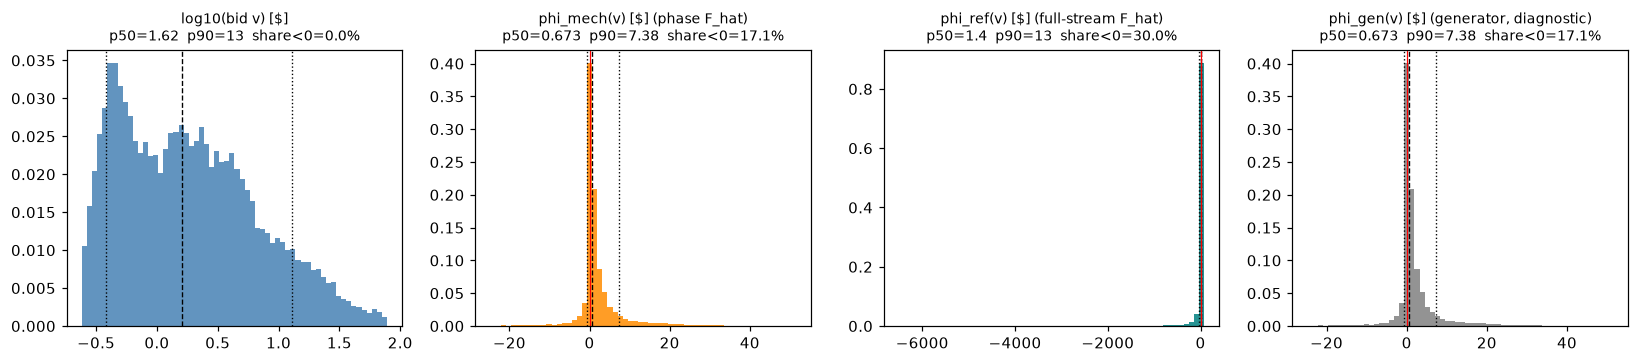

In [7]:
def qhist(ax, x, color, title, w=None, bins=60, logx=False):
    x = np.asarray(x, float)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    xv = np.log10(np.clip(x, 1e-12, None)) if logx else x
    lo, hi = _weighted_quantile(xv, w, 0.01), _weighted_quantile(xv, w, 0.99)
    ax.hist(xv, bins=bins, range=(lo, hi), weights=w / w.sum(), color=color, alpha=0.85)
    for q, ls in ((0.10, ":"), (0.50, "--"), (0.90, ":")):
        ax.axvline(_weighted_quantile(xv, w, q), color="k", ls=ls, lw=0.9)
    if not logx and lo < 0 < hi:
        ax.axvline(0, color="r", lw=0.8)
    neg = np.average(x < 0, weights=w)
    title = title.replace("$", r"\$")                     # no mathtext between two '$'
    ax.set_title(f"{title}\np50={_weighted_quantile(x, w, .5):.3g}  p90={_weighted_quantile(x, w, .9):.3g}"
                 f"  share<0={100 * neg:.1f}%", fontsize=9)

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
qhist(ax[0], A0["v"], C_BID, "log10(bid v) [$]", logx=True)
qhist(ax[1], A0["phi_mech"], C_PI, "phi_mech(v) [$] (phase F_hat)")
qhist(ax[2], R0["phi_ref"], "teal", "phi_ref(v) [$] (full-stream F_hat)")
qhist(ax[3], A0["phi_gen"], "gray", "phi_gen(v) [$] (generator, diagnostic)")
plt.tight_layout(); plt.show()

### 1.b SW, Π, C$ = s_C·K: job level (stream) and type level (full-stream reference types, weights p_j)

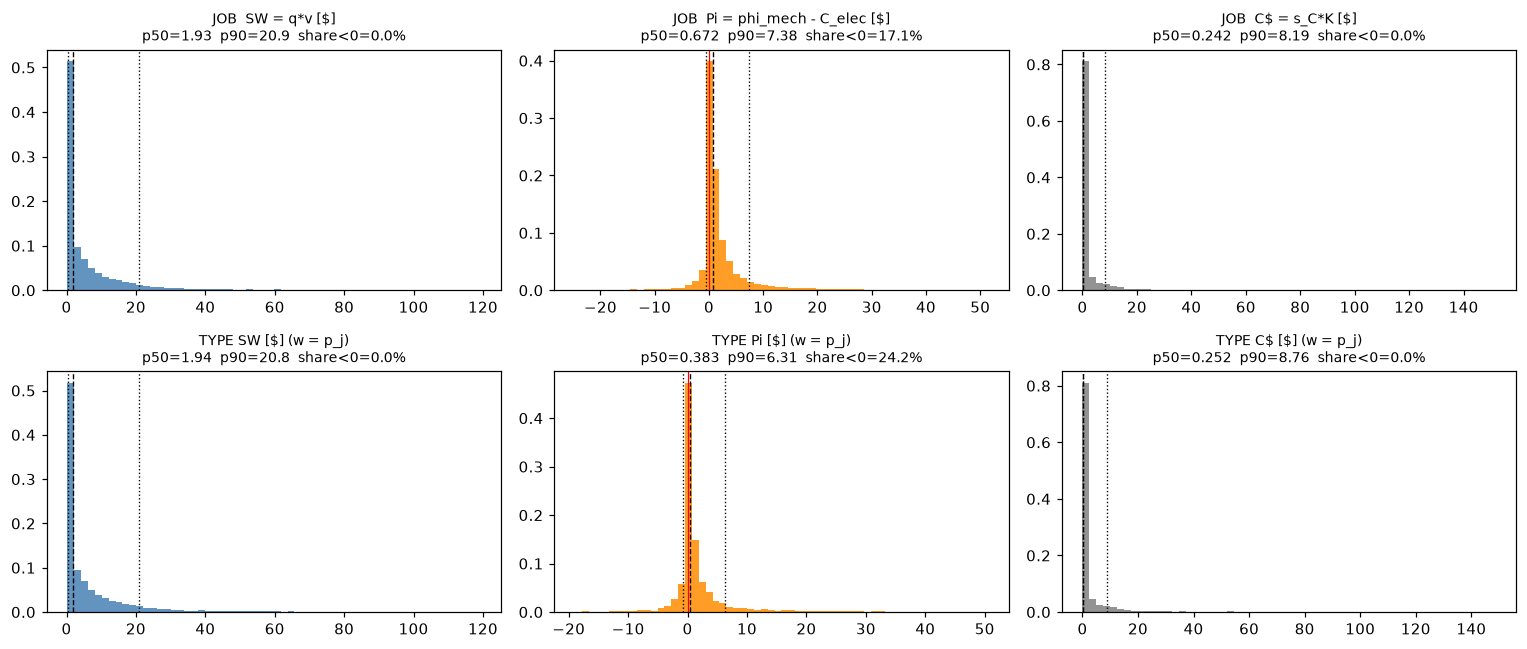

In [8]:
st_ref0 = R0["st_ref"]
_, prio_ref, _ = type_arrays(st_ref0.type_space, st_ref0.grid)
pop = st_ref0.p > 0
wt = st_ref0.p[pop]
SW_t = (prio_ref * st_ref0.v_bar)[pop]
PI_t = (st_ref0.phi_bar - st_ref0.C_elec_bar)[pop]
C_t = SC0 * st_ref0.C_carbon_bar[pop]

fig, ax = plt.subplots(2, 3, figsize=(14, 6))
qhist(ax[0, 0], A0["SW"], C_SW, "JOB  SW = q*v [$]")
qhist(ax[0, 1], A0["PI"], C_PI, "JOB  Pi = phi_mech - C_elec [$]")
qhist(ax[0, 2], A0["Cusd"], C_C, "JOB  C$ = s_C*K [$]")
qhist(ax[1, 0], SW_t, C_SW, "TYPE SW [$] (w = p_j)", w=wt)
qhist(ax[1, 1], PI_t, C_PI, "TYPE Pi [$] (w = p_j)", w=wt)
qhist(ax[1, 2], C_t, C_C, "TYPE C$ [$] (w = p_j)", w=wt)
plt.tight_layout(); plt.show()

desc = []
for lvl, (sw, pi, cu, w) in {"job": (A0["SW"], A0["PI"], A0["Cusd"], None),
                             "type": (SW_t, PI_t, C_t, wt)}.items():
    for name, x in (("SW", sw), ("Pi", pi), ("C$", cu)):
        x = np.asarray(x, float); ww = np.ones_like(x) if w is None else w
        desc.append({"level": lvl, "objective": name, "min": x.min(),
                     **{f"p{int(q * 100)}": _weighted_quantile(x, ww, q) for q in (.01, .1, .5, .9, .99)},
                     "max": x.max(), "share<0 %": 100 * np.average(x < 0, weights=ww)})
display(pd.DataFrame(desc).set_index(["level", "objective"]).style.format(precision=4))

### 1.c Negative base reward R = λ1·SW + λ2·Π − λ3·s_C·K

Job level: R_job of every stream arrival (φ of its phase). Type level: r̃ of the state used in each phase, weighted
by that state's p̂ (populated types); "reference" = full-stream types weighted by p_ref. "no carbon" drops −λ3·s_C·K.

In [9]:
neg_rows = [{"level": "job", "scope": "all phases", "n": len(A0),
             "R<0 %": 100 * (A0["R_job"] < 0).mean(), "R<0 no carbon %": 100 * (A0["R_nocarb"] < 0).mean()}]
for m, g in A0.groupby("m"):
    neg_rows.append({"level": "job", "scope": f"phase {m}", "n": len(g),
                     "R<0 %": 100 * (g["R_job"] < 0).mean(),
                     "R<0 no carbon %": 100 * (g["R_nocarb"] < 0).mean()})
for m, st in enumerate(M0.states, start=1):
    pp = st.p > 0
    neg_rows.append({"level": "type", "scope": f"phase {m} state", "n": int(pp.sum()),
                     "R<0 %": 100 * np.average(st.r_tilde[pp] < 0, weights=st.p[pp]),
                     "R<0 no carbon %": 100 * np.average(st.r_rev[pp] < 0, weights=st.p[pp])})
neg_rows.append({"level": "type", "scope": "reference (full stream)", "n": int(pop.sum()),
                 "R<0 %": 100 * np.average(st_ref0.r_tilde[pop] < 0, weights=wt),
                 "R<0 no carbon %": 100 * np.average(st_ref0.r_rev[pop] < 0, weights=wt)})
display(pd.DataFrame(neg_rows).set_index(["level", "scope"]).style.format(precision=2))

neg = A0[A0["R_job"] < 0]
na = neg[neg["admit"]]
print(f"jobs with R_job < 0: {len(neg):,} / {len(A0):,} ({100 * len(neg) / len(A0):.1f}%)  -> admitted: "
      f"{len(na):,} ({100 * len(na) / max(len(neg), 1):.1f}% of the negative ones)")
print("decision of negative-R jobs:", neg["decision"].value_counts().to_dict())
if len(na):
    print("admitted negative-R jobs (the oracle sees the TYPE reward r~, not R_job):")
    print(f"  share with type score r~ - tau^T v > 0      : {100 * (na['score'] > 0).mean():.1f}%")
    print(f"  mean r~_type = {na['r_tilde'].mean():.3f} $   mean R_job = {na['R_job'].mean():.3f} $   "
          f"mean gap R_job - r~ = {(na['R_job'] - na['r_tilde']).mean():.3f} $")
    print(f"  share with Pi_job < 0                        : {100 * (na['PI'] < 0).mean():.1f}%")
    print(f"  share with phi_mech < 0                      : {100 * (na['phi_mech'] < 0).mean():.1f}%")
    print(f"  share with R_job >= 0 without carbon (carbon flips the sign): "
          f"{100 * (na['R_nocarb'] >= 0).mean():.1f}%")

jobs with R_job < 0: 2,468 / 15,308 (16.1%)  -> admitted: 514 (20.8% of the negative ones)
decision of negative-R jobs: {'oracle reject': 1713, 'accepted': 514, 'thinning reject': 241}
admitted negative-R jobs (the oracle sees the TYPE reward r~, not R_job):
  share with type score r~ - tau^T v > 0      : 100.0%
  mean r~_type = 6.333 $   mean R_job = -15.899 $   mean gap R_job - r~ = -22.232 $
  share with Pi_job < 0                        : 89.5%
  share with phi_mech < 0                      : 89.5%
  share with R_job >= 0 without carbon (carbon flips the sign): 26.3%


## Section 2: Per-phase margin (C.2, baseline scale)

One figure per phase, x = arrival tick (jobs arriving in that phase only). Grey dots: job reward R_job.
Blue line: rolling median of the type reward r̃_type. Purple line: rolling median of the shadow-price cost τᵀv_type.
Markers: margin r̃_type − τᵀv_type by final decision. Black line: rolling median of the margin, shaded green
where > 0 and red where < 0. y axis: symlog (linear within ±1 $). Phases with more than `N_PLOT` arrivals are
randomly subsampled to `N_PLOT` points (fixed seed); rolling medians use every arrival of the phase.

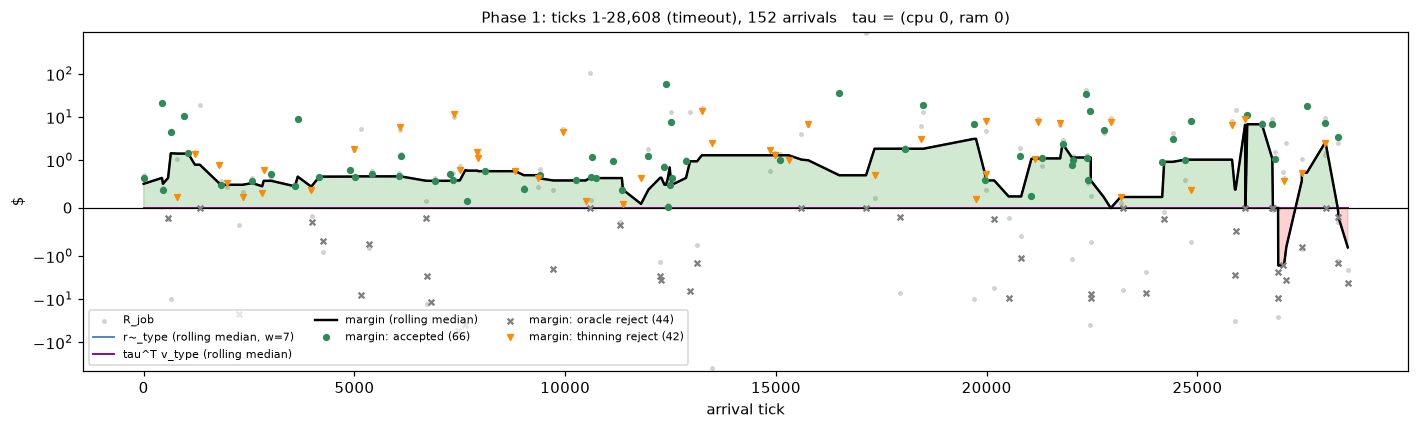

phase 1: share margin>0 = 71.1%   median margin = 0.648 $   (tau = 0: shadow cost = 0, margin = r~_type)


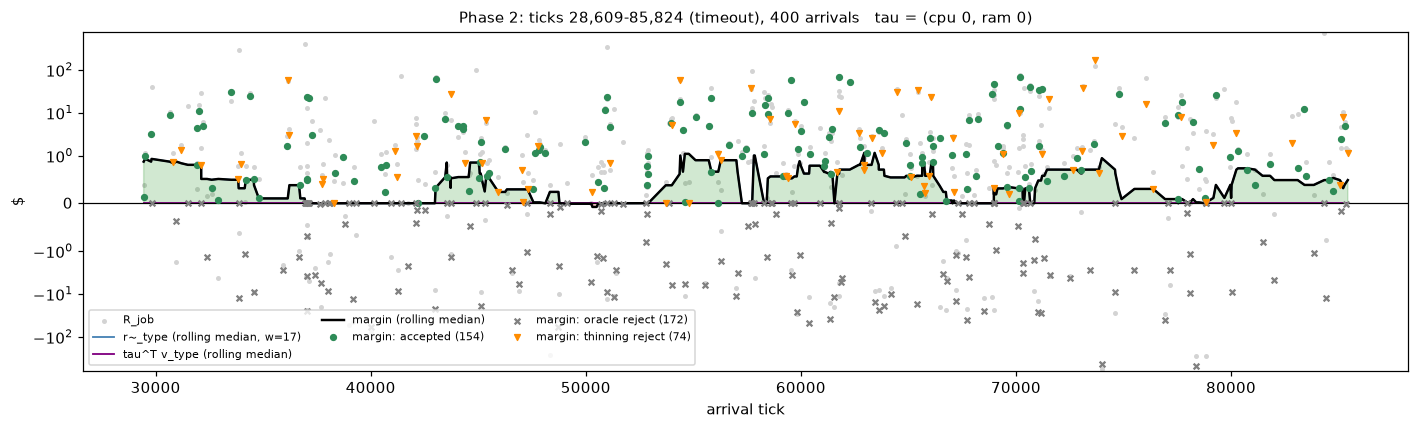

phase 2: share margin>0 = 57.0%   median margin = 0.306 $   (tau = 0: shadow cost = 0, margin = r~_type)


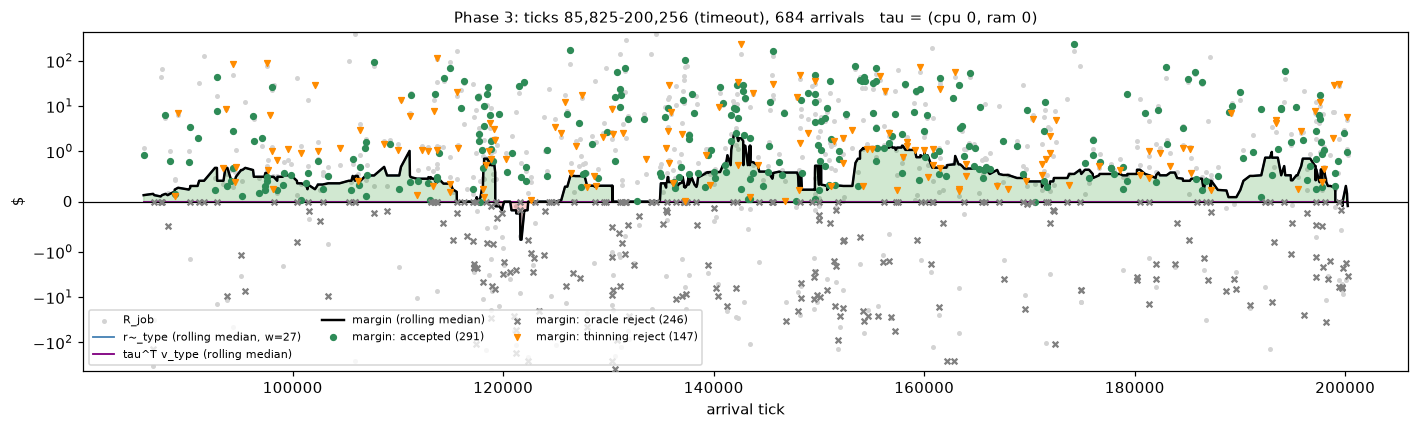

phase 3: share margin>0 = 64.0%   median margin = 0.488 $   (tau = 0: shadow cost = 0, margin = r~_type)


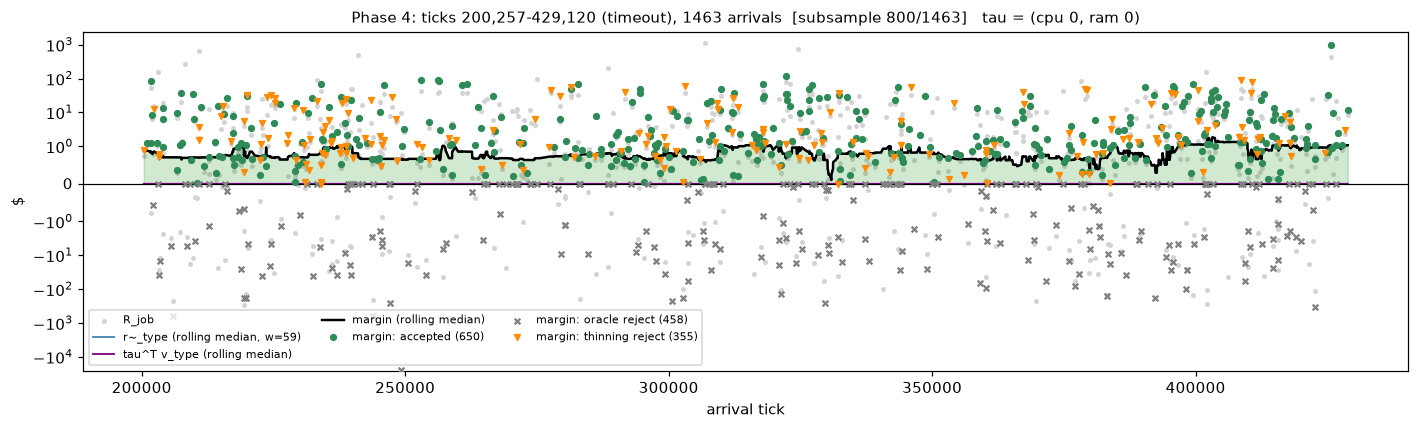

phase 4: share margin>0 = 68.7%   median margin = 0.799 $   (tau = 0: shadow cost = 0, margin = r~_type)


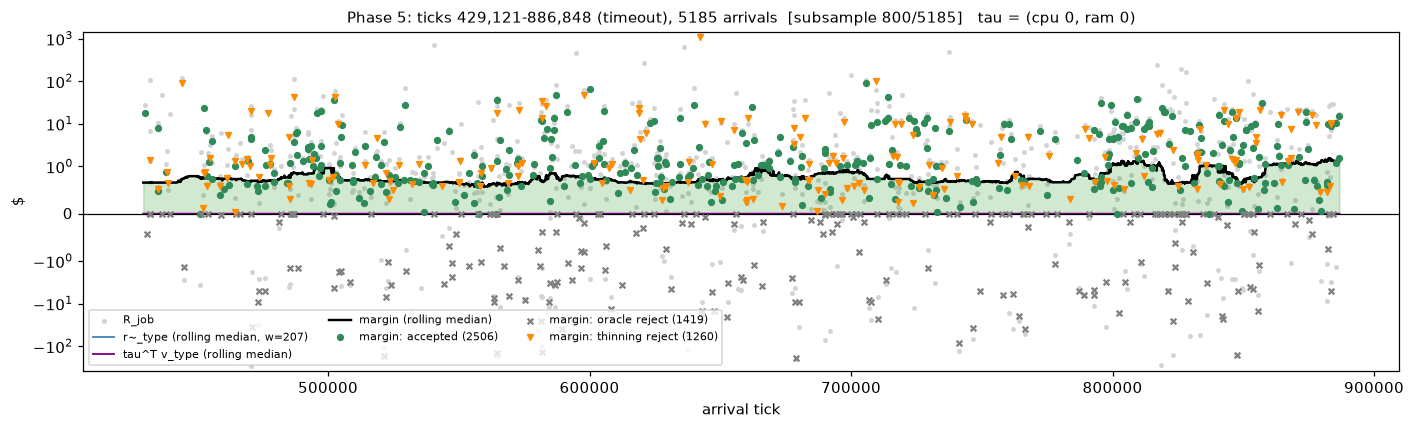

phase 5: share margin>0 = 72.6%   median margin = 0.740 $   (tau = 0: shadow cost = 0, margin = r~_type)


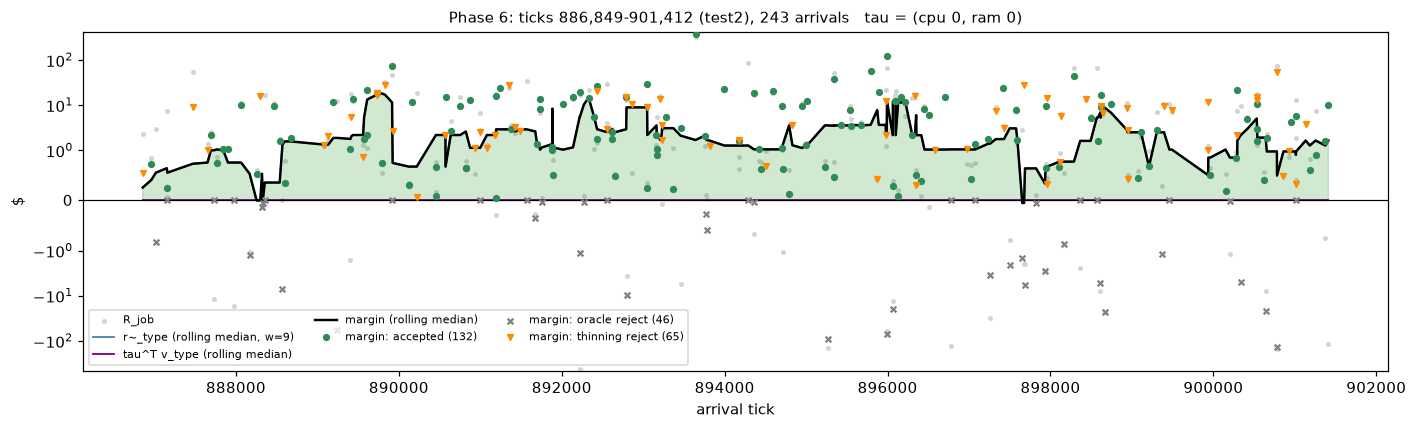

phase 6: share margin>0 = 81.1%   median margin = 1.690 $   (tau = 0: shadow cost = 0, margin = r~_type)


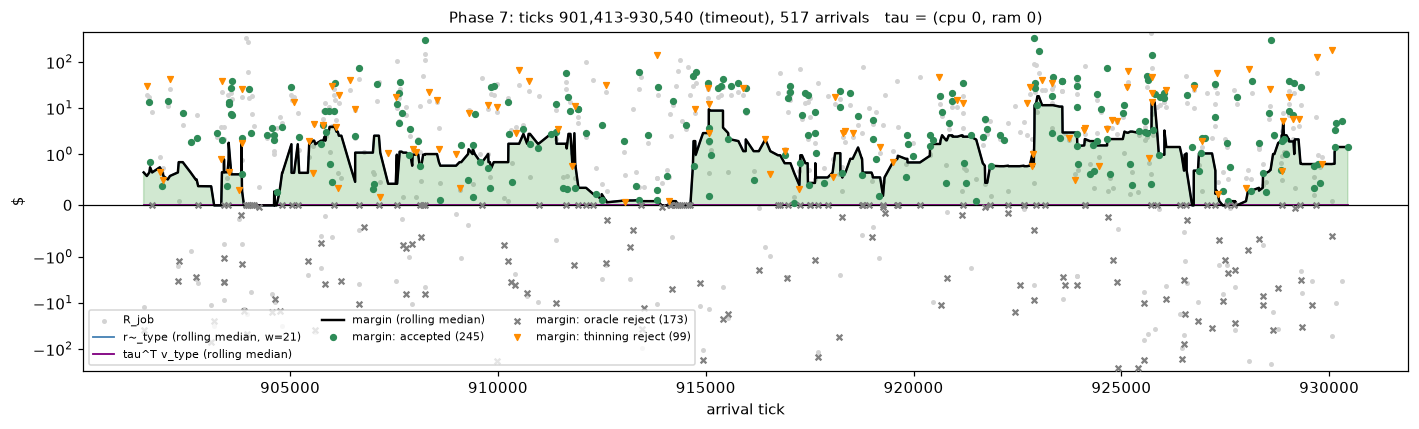

phase 7: share margin>0 = 66.5%   median margin = 0.909 $   (tau = 0: shadow cost = 0, margin = r~_type)


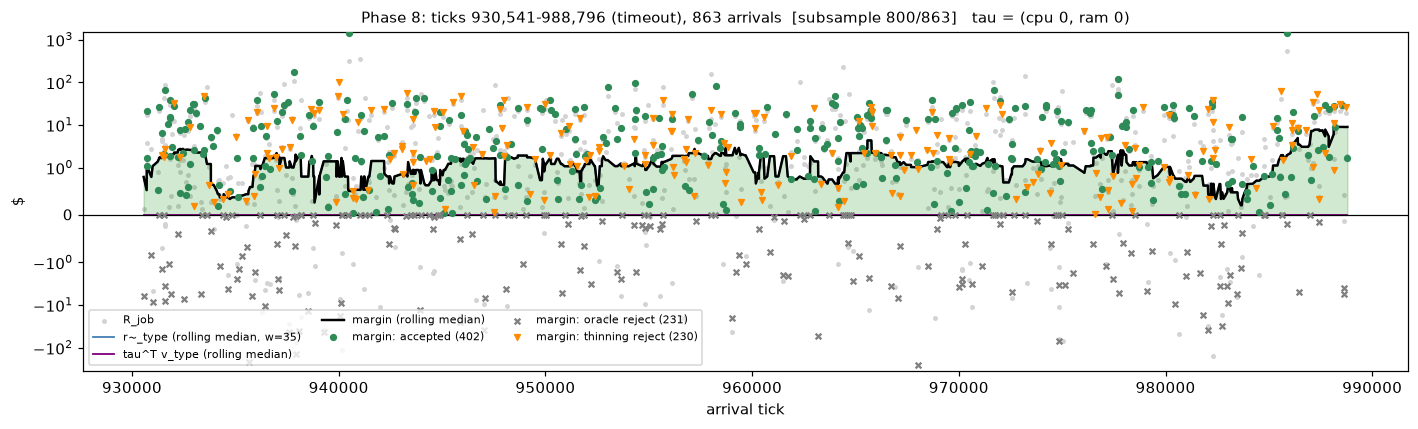

phase 8: share margin>0 = 73.2%   median margin = 1.341 $   (tau = 0: shadow cost = 0, margin = r~_type)


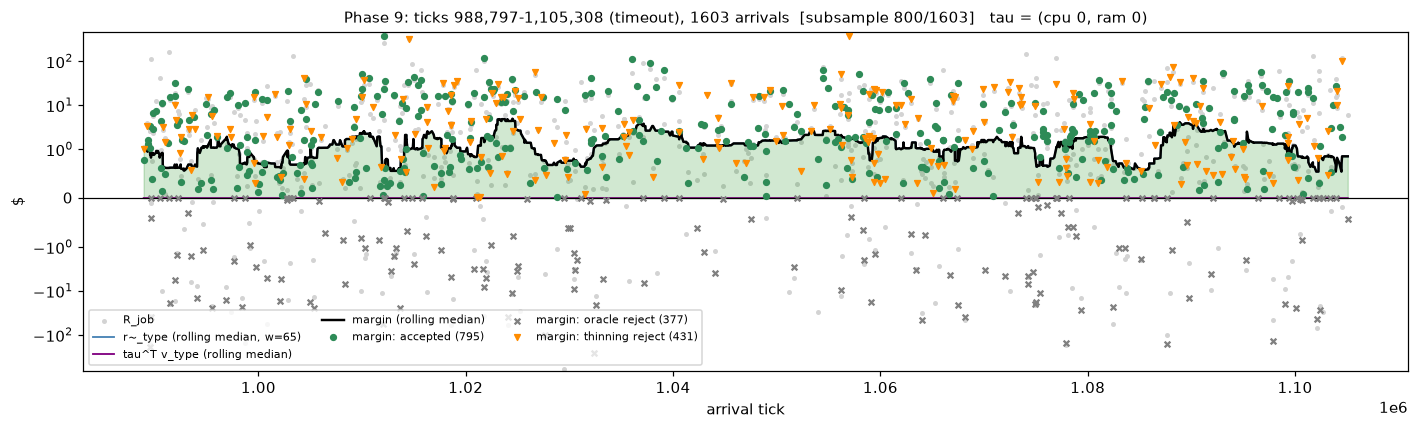

phase 9: share margin>0 = 76.5%   median margin = 1.222 $   (tau = 0: shadow cost = 0, margin = r~_type)


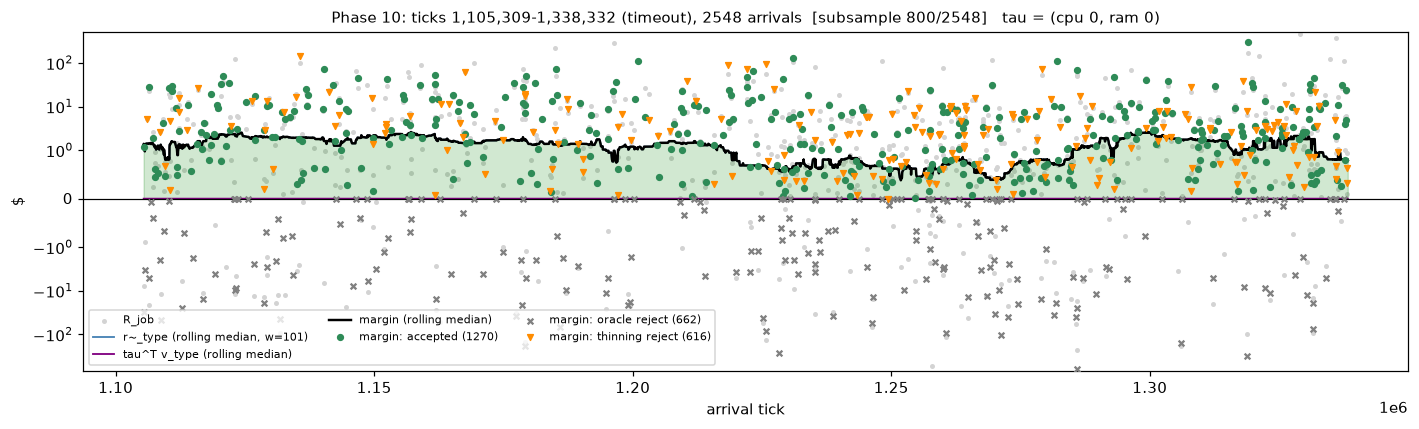

phase 10: share margin>0 = 74.0%   median margin = 1.035 $   (tau = 0: shadow cost = 0, margin = r~_type)


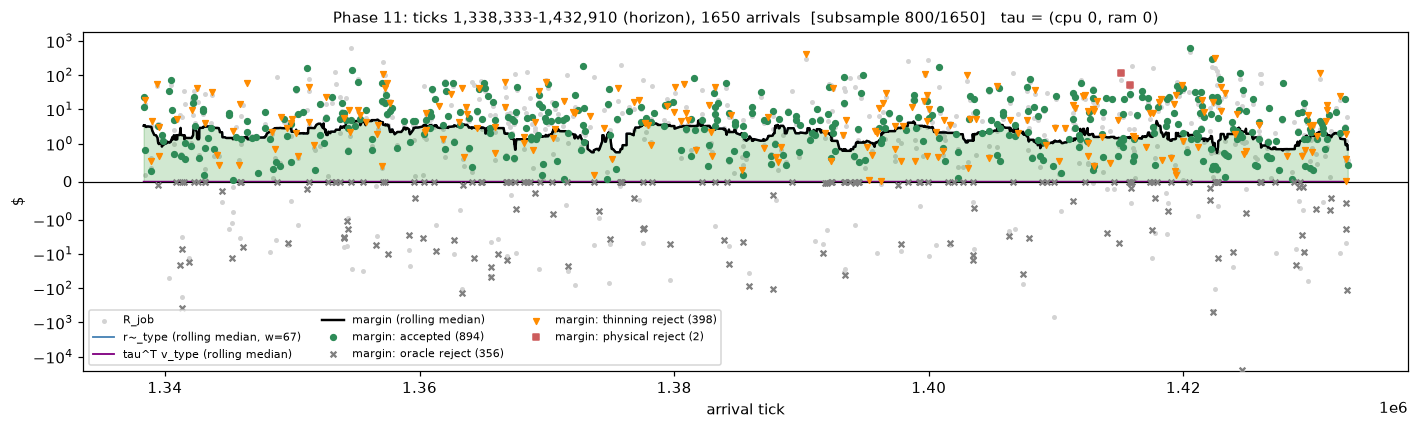

phase 11: share margin>0 = 78.4%   median margin = 1.952 $   (tau = 0: shadow cost = 0, margin = r~_type)


In [10]:
N_PLOT = 800
for m, g_all in A0.groupby("m"):
    p = PH0[PH0["m"] == m].iloc[0]
    st = M0.states[m - 1]
    g_all = g_all.sort_values("t")
    w = max(5, len(g_all) // 25) | 1
    roll = lambda col: g_all[col].rolling(w, center=True, min_periods=1).median()
    rm_r, rm_s, rm_m = roll("r_tilde"), roll("shadow_cost"), roll("score")
    g = g_all.sample(N_PLOT, random_state=0).sort_values("t") if len(g_all) > N_PLOT else g_all
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.scatter(g["t"], g["R_job"], s=5, color="lightgray", label="R_job", zorder=1)
    ax.plot(g_all["t"], rm_r, color="steelblue", lw=1.2, label=f"r~_type (rolling median, w={w})")
    ax.plot(g_all["t"], rm_s, color="purple", lw=1.2, label="tau^T v_type (rolling median)")
    ax.plot(g_all["t"], rm_m, color="k", lw=1.6, label="margin (rolling median)")
    mm = rm_m.to_numpy()
    ax.fill_between(g_all["t"], 0, mm, where=mm > 0, color="green", alpha=0.18, interpolate=True)
    ax.fill_between(g_all["t"], 0, mm, where=mm < 0, color="red", alpha=0.18, interpolate=True)
    for d in DEC_ORDER:
        h = g[g["decision"] == d]
        if len(h):
            col, mk = DEC_STYLE[d]
            ax.scatter(h["t"], h["score"].replace(-np.inf, np.nan), s=14, color=col, marker=mk,
                       label=f"margin: {d} ({(g_all['decision'] == d).sum()})", zorder=3)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_yscale("symlog", linthresh=1.0)
    ax.set_xlabel("arrival tick"); ax.set_ylabel("$")
    sub = f"  [subsample {len(g)}/{len(g_all)}]" if len(g) < len(g_all) else ""
    ax.set_title(f"Phase {m}: ticks {p['tau_start']:,}-{p['tau_end']:,} ({p['reason']}), {len(g_all)} arrivals{sub}"
                 f"   tau = (cpu {st.tau[0]:.4g}, ram {st.tau[1]:.4g})", fontsize=10)
    ax.legend(fontsize=7, ncol=3, loc="lower left")
    plt.tight_layout(); plt.show()
    zero_tau = np.allclose(st.tau, 0)
    print(f"phase {m}: share margin>0 = {100 * (g_all['score'] > 0).mean():.1f}%   "
          f"median margin = {np.nanmedian(g_all['score'].replace(-np.inf, np.nan)):.3f} $"
          + ("   (tau = 0: shadow cost = 0, margin = r~_type)" if zero_tau else ""))

## Section 3: Results per phase (C.3, baseline scale)

Rejections by reason: IR (no type), oracle (r̃ − τᵀv ≤ 0), thinning (oracle yes, U(t) = 0), physical
(oracle yes, U(t) = 1, U + A > c). Reward = logged dollars; its three parts are λ1·SW, λ2·Π and −λ3·s_C·K of the
admitted jobs (they sum to the total). Occupancy = exact step function from the event log (heap releases), as a
fraction of the current capacity, time-weighted over the phase's ticks.

In [11]:
def phase_table(run):
    a, ph, model = run["A"], run["ph"], run["model"]
    c = model.c
    rows = []
    for _, p in ph.iterrows():
        m = int(p["m"]); g = a[a["m"] == m]; adm = g[g["admit"]]
        mean, peak = occ_stats(run["te"], run["Ue"], int(p["tau_start"]), int(p["tau_end"]))
        st = model.states[m - 1]
        # cross-check against the loop's own per-phase counters
        assert (g["decision"] == "thinning reject").sum() == p["n_thinned"]
        assert (g["decision"] == "physical reject").sum() == p["n_phys_reject"]
        assert len(adm) == p["n_admitted"] and np.isclose(adm["R"].sum(), p["R"])
        rows.append({
            "phase": m, "start": int(p["tau_start"]), "end": int(p["tau_end"]), "steps": int(p["W"]),
            "jobs": len(g), "end reason": p["reason"], "admitted": len(adm),
            "rej IR": int((g["decision"] == "IR reject").sum()),
            "rej oracle": int((g["decision"] == "oracle reject").sum()),
            "rej thinning": int((g["decision"] == "thinning reject").sum()),
            "rej physical": int((g["decision"] == "physical reject").sum()),
            "adm rate %": 100 * len(adm) / max(len(g), 1),
            "R $": adm["R"].sum(), "l1*SW $": L1 * adm["SW"].sum(), "l2*Pi $": L2 * adm["PI"].sum(),
            "-l3*s_C*K $": -L3 * adm["Cusd"].sum(),
            "adm R<0": int((adm["R"] < 0).sum()), "adm R<0 %": 100 * (adm["R"] < 0).mean() if len(adm) else 0.0,
            "occ cpu mean %": 100 * mean[0] / c[0], "occ ram mean %": 100 * mean[1] / c[1],
            "occ cpu peak %": 100 * peak[0] / c[0], "occ ram peak %": 100 * peak[1] / c[1],
            "tau_cpu start": st.tau[0], "tau_ram start": st.tau[1],
        })
    df = pd.DataFrame(rows).set_index("phase")
    tot = df.sum(numeric_only=True)
    g = run["A"]; adm = g[g["admit"]]
    mean, peak = occ_stats(run["te"], run["Ue"], 1, int(model.ds.T))
    tot.update({"start": 1, "end": int(model.ds.T), "adm rate %": 100 * len(adm) / len(g),
                "adm R<0 %": 100 * (adm["R"] < 0).mean(), "occ cpu mean %": 100 * mean[0] / c[0],
                "occ ram mean %": 100 * mean[1] / c[1], "occ cpu peak %": 100 * peak[0] / c[0],
                "occ ram peak %": 100 * peak[1] / c[1], "tau_cpu start": np.nan, "tau_ram start": np.nan})
    df.loc["total"] = tot
    df.loc["total", "end reason"] = ""
    return df

PT0 = phase_table(R0)
display(PT0.style.format(precision=3))
assert np.isclose(PT0.loc["total", "R $"], R0["res"].summary["R_total"])

,start,end,steps,jobs,end reason,admitted,rej IR,rej oracle,rej thinning,rej physical,adm rate %,R $,l1*SW $,l2*Pi $,-l3*s_C*K $,adm R<0,adm R<0 %,occ cpu mean %,occ ram mean %,occ cpu peak %,occ ram peak %,tau_cpu start,tau_ram start
phase,,,,,,,,,,,,,,,,,,,,,,,
1,1.000,28608.000,28608.000,152.000,timeout,66.000,0.000,44.000,42.000,0.000,43.421,253.634,245.331,51.961,-43.658,4.000,6.061,1.236,1.107,12.716,14.878,0.000,0.000
2,28609.000,85824.000,57216.000,400.000,timeout,154.000,0.000,172.000,74.000,0.000,38.500,1078.584,971.513,364.911,-257.840,6.000,3.896,3.991,3.898,47.638,51.395,0.000,0.000
3,85825.000,200256.000,114432.000,684.000,timeout,291.000,0.000,246.000,147.000,0.000,42.544,1912.754,2120.434,610.276,-817.957,21.000,7.216,6.034,6.599,71.240,76.200,0.000,0.000
4,200257.000,429120.000,228864.000,1463.000,timeout,650.000,0.000,458.000,355.000,0.000,44.429,3231.133,3544.228,943.673,-1256.769,66.000,10.154,4.834,5.526,62.132,73.111,0.000,0.000
5,429121.000,886848.000,457728.000,5185.000,timeout,2506.000,0.000,1419.000,1260.000,0.000,48.332,14188.843,13293.967,3571.472,-2676.597,160.000,6.385,5.182,5.600,55.373,63.220,0.000,0.000
6,886849.000,901412.000,14564.000,243.000,test2,132.000,0.000,46.000,65.000,0.000,54.321,1306.040,1479.897,166.827,-340.684,7.000,5.303,11.757,13.596,40.893,51.476,0.000,0.000
7,901413.000,930540.000,29128.000,517.000,timeout,245.000,0.000,173.000,99.000,0.000,47.389,1641.656,1888.403,324.572,-571.319,24.000,9.796,14.812,17.079,70.530,74.791,0.000,0.000
8,930541.000,988796.000,58256.000,863.000,timeout,402.000,0.000,231.000,230.000,0.000,46.582,4076.595,4096.884,960.036,-980.325,19.000,4.726,14.545,15.010,67.542,65.047,0.000,0.000
9,988797.000,1105308.000,116512.000,1603.000,timeout,795.000,0.000,377.000,431.000,0.000,49.595,6494.030,6092.110,1473.179,-1071.259,52.000,6.541,9.098,9.647,60.778,65.460,0.000,0.000


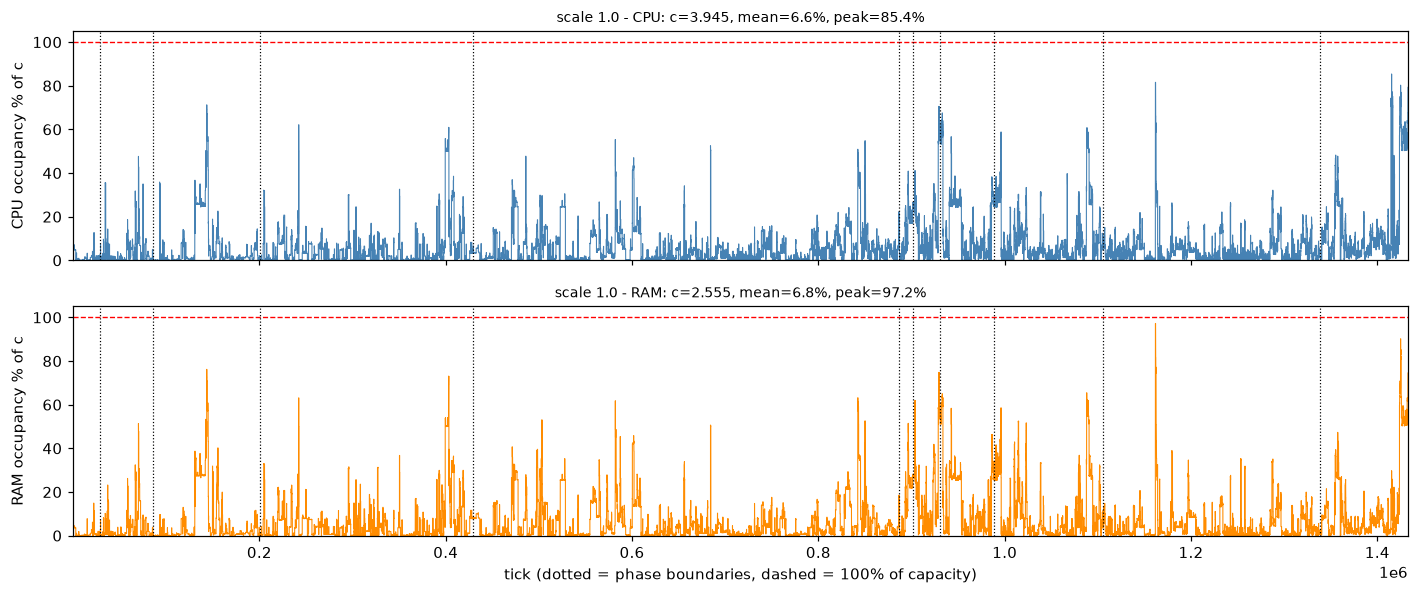

In [12]:
def plot_occupancy(ax_cpu, ax_ram, run, title=""):
    model = run["model"]; c = model.c; T = int(model.ds.T)
    te, Ue = run["te"], run["Ue"]
    x = np.r_[1, te, T]
    for ax, i, col, name in ((ax_cpu, 0, C_CPU, "CPU"), (ax_ram, 1, C_RAM, "RAM")):
        y = 100 * np.r_[0.0, Ue[:, i], Ue[-1, i]] / c[i]
        ax.step(x, y, where="post", color=col, lw=0.7)
        ax.axhline(100, color="red", ls="--", lw=0.9)
        for b in run["ph"]["tau_start"].iloc[1:]:
            ax.axvline(b, color="k", ls=":", lw=0.8)
        ax.set_ylim(0, 105); ax.set_xlim(1, T)
        ax.set_ylabel(f"{name} occupancy % of c")
        ax.set_title(f"{title}{name}: c={c[i]:.4g}, mean={100 * np.average(Ue[:-1, i], weights=np.diff(te)) / c[i] if len(te) > 1 else 0:.1f}%"
                     f", peak={100 * Ue[:, i].max() / c[i]:.1f}%", fontsize=9)

fig, ax = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
plot_occupancy(ax[0], ax[1], R0, title=f"scale {BASELINE_SCALE} - ")
ax[1].set_xlabel("tick (dotted = phase boundaries, dashed = 100% of capacity)")
plt.tight_layout(); plt.show()

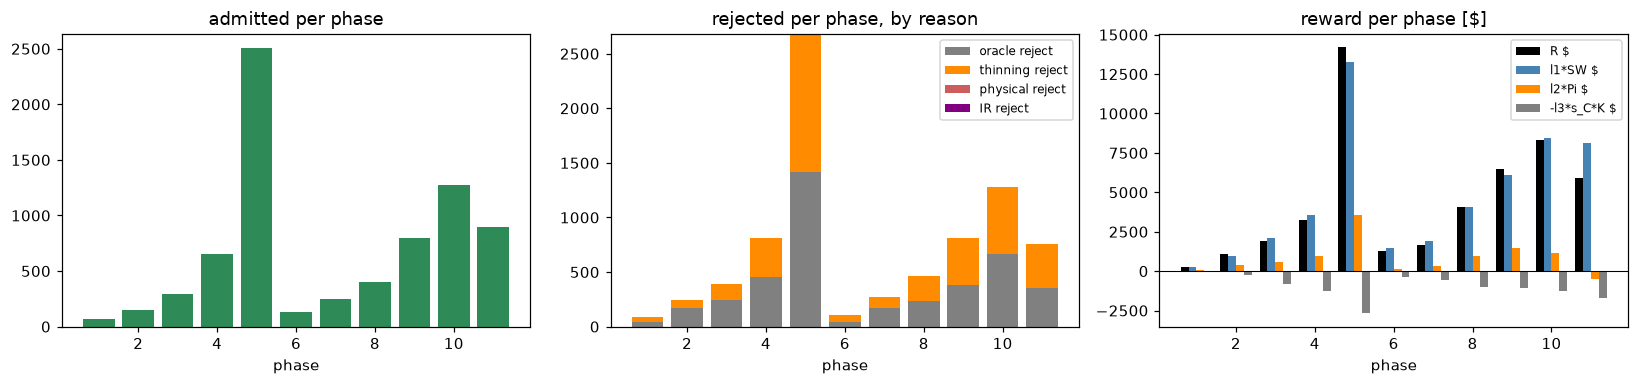

In [13]:
body = PT0.drop(index="total")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
idx = body.index.astype(int)
ax[0].bar(idx, body["admitted"], color="seagreen")
ax[0].set_title("admitted per phase"); ax[0].set_xlabel("phase")
bottom = np.zeros(len(body))
for col, d in (("rej oracle", "oracle reject"), ("rej thinning", "thinning reject"),
               ("rej physical", "physical reject"), ("rej IR", "IR reject")):
    ax[1].bar(idx, body[col], bottom=bottom, color=DEC_STYLE[d][0], label=d)
    bottom += body[col].to_numpy(float)
ax[1].legend(fontsize=8); ax[1].set_title("rejected per phase, by reason"); ax[1].set_xlabel("phase")
wb = 0.2
for k, (col, cc) in enumerate((("R $", "k"), ("l1*SW $", C_SW), ("l2*Pi $", C_PI), ("-l3*s_C*K $", C_C))):
    ax[2].bar(idx + (k - 1.5) * wb, body[col], width=wb, color=cc, label=col)
ax[2].axhline(0, color="k", lw=0.7); ax[2].legend(fontsize=8); ax[2].set_title("reward per phase [$]")
ax[2].set_xlabel("phase")
plt.tight_layout(); plt.show()

## Section 4: Accuracy per phase (C.4, baseline scale)

**All references are ORACLE quantities** (full stream, true labels; not available online). Phase k runs with the
state built at the end of phase k−1 (phase 1: Phase 0 on H). Because the valuation grid is refit at every phase,
each comparison is done **on phase k's own type space**: the full stream is re-assigned to phase k's types to
build p_ref, d_ref and r_ref (with φ_ref, s_C frozen).

* TV(p̂_k, p_ref): both normalised to sum 1 over types; thin mass = p_ref mass of types with N_j < n_type_min in the
  data that built the state.
* d̂ error: |d̂ − d_ref| / d_ref over types with p_ref > 0 (p_ref-weighted mean and median). CI: 95% normal half-width
  1.96·sd/√M of the observed durations that built the state, relative to their mean, over types with M ≥ 2.
* KS(F̂_k, F_emp): pooled lognormal F̂_k vs the empirical CDF of all stream bids; φ error: mean |φ̂_k(v) − φ_ref(v)|.
* reward error: p_ref-weighted mean |r̃_k − r_ref| ($ and relative to mean |r_ref|) and sign-mismatch rate.
* ‖τ̂_k − τ*‖ with τ* the dual of the full-stream hindsight LP.
* decision agreement: share of phase-k arrivals where k̂ (phase oracle) equals the hindsight oracle
  1[r_ref − τ*ᵀv_ref > 0] on the reference types; also vs the offline job-level OPT x*.
* theory (error_params.py, Appendix A): ε_D, η(W_prev), p_U at the phase start/end, CI¹(W), ε̃_Test2(W), ε_Test3(W).

In [14]:
def accuracy_table(run):
    model, a, ph, st_ref = run["model"], run["A"], run["ph"], run["st_ref"]
    S, ds, ep = model.stream, model.ds, model.ep
    nmin = BASE.phase_transition.n_type_min
    phi_ref = run["phi_ref"]
    v_sorted = np.sort(S.v); n = S.n
    e_hi, e_lo = np.arange(1, n + 1) / n, np.arange(n) / n
    rows = []
    for k, st in enumerate(model.states, start=1):
        nT = st.n_types
        tid = types_under(st, S); ok = tid >= 0
        N_ref = np.bincount(tid[ok], minlength=nT).astype(float)
        p_ref = N_ref / N_ref.sum()
        p_hat = st.p / st.p.sum()
        if k == 1:
            W_used, n_used = ds.H_span_steps, ds.H.n
            H = ds.H
            tid_o = assign_type_ids(st.type_space, st.grid.assign(st.bids.v_rate, st.myerson), H.priority, H.hw_idx)
            D_o = H.duration_steps
        else:
            prev = ph[ph["m"] == k - 1].iloc[0]
            W_used, n_used = int(prev["W"]), int(prev["n_arrivals"])
            obs = a.loc[(a["m"] == k - 1) & a["admit"], "i"].to_numpy()
            tid_o, D_o = types_under(st, S, obs), S.D[obs]
        N_used = np.rint(st.p * W_used)
        mean_by = lambda x: np.divide(np.bincount(tid[ok], weights=np.asarray(x, float)[ok], minlength=nT),
                                      N_ref, out=np.zeros(nT), where=N_ref > 0)
        d_ref = mean_by(S.D)
        mk = p_ref > 0
        rel_d = np.abs(st.d_bar[mk] - d_ref[mk]) / d_ref[mk]
        oo = tid_o >= 0
        M = np.bincount(tid_o[oo], minlength=nT).astype(float)
        s1 = np.bincount(tid_o[oo], weights=D_o[oo].astype(float), minlength=nT)
        s2 = np.bincount(tid_o[oo], weights=D_o[oo].astype(float) ** 2, minlength=nT)
        mu = np.divide(s1, M, out=np.zeros(nT), where=M > 0)
        var = np.divide(s2 - M * mu ** 2, M - 1, out=np.zeros(nT), where=M > 1)
        ci = np.divide(1.96 * np.sqrt(np.clip(var, 0, None) / np.maximum(M, 1)), mu,
                       out=np.full(nT, np.nan), where=(M > 1) & (mu > 0))
        mc = mk & np.isfinite(ci)
        F_hat = lognorm.cdf(v_sorted, s=st.myerson.sigma, scale=np.exp(st.myerson.mu))
        ks = max(np.abs(F_hat - e_hi).max(), np.abs(F_hat - e_lo).max())
        phi_k = np.asarray(st.myerson.phi(S.v))
        _, prio, A_t = type_arrays(st.type_space, st.grid)
        r_ref, *_ = scalarized_reward(prio, mean_by(S.v), mean_by(phi_ref), mean_by(S.C_elec), mean_by(S.C_carbon),
                                      p_ref, A_t * d_ref[:, None], ds, BASE, common_scale=model.s_norm,
                                      carbon_price=model.state0.carbon_price)
        w = p_ref[mk]
        r_err = np.average(np.abs(st.r_tilde[mk] - r_ref[mk]), weights=w)
        g = a[a["m"] == k]
        W = int(ph.loc[ph["m"] == k, "W"].iloc[0]); W_prev = int(ph.loc[ph["m"] == k, "W_prev"].iloc[0])
        rows.append({
            "phase": k, "n used (arrivals)": n_used, "built from": "H (Phase 0)" if k == 1 else f"phase {k - 1}",
            "TV(p_hat,p_ref)": 0.5 * np.abs(p_hat - p_ref).sum(),
            "thin mass (N_j<n_type_min)": p_ref[N_used < nmin].sum(),
            "d rel err mean": np.average(rel_d, weights=w),
            "d rel err median": _weighted_quantile(rel_d, w, 0.5),
            "d CI rel half-width": np.average(ci[mc], weights=p_ref[mc]) if mc.any() else np.nan,
            "d CI mass covered": p_ref[mc].sum(),
            "KS(F_hat,F_emp)": ks,
            "phi mean abs err $": np.mean(np.abs(phi_k - phi_ref)),
            "phi rel err": np.mean(np.abs(phi_k - phi_ref)) / np.mean(np.abs(phi_ref)),
            "r mean abs err $": r_err,
            "r rel err": r_err / np.average(np.abs(r_ref[mk]), weights=w),
            "r sign mismatch": np.average(np.sign(st.r_tilde[mk]) != np.sign(r_ref[mk]), weights=w),
            "||tau_k - tau*||": float(np.linalg.norm(st.tau - st_ref.tau)),
            "agree hindsight oracle": (g["k_hat"] == g["k_hat_ref"]).mean(),
            "agree offline x*": (g["k_hat"].to_numpy() == run["opt"]["x"][g["i"].to_numpy()]).mean(),
            "eps_D": ep.eps_D, "eta(W_prev)": float(ep.eta(W_prev)),
            "p_U start": ep.p_U(W_prev, 1), "p_U end": ep.p_U(W_prev, W),
            "CI1(W)": float(ep.CI1(W)), "eps_Test2(W)": float(ep.eps_test2(W_prev, W)),
            "eps_Test3(W)": float(ep.eps_test3(W)),
            "max(Test2 lhs - thr)": float((g["test2_lhs"] - g["test2_thr"]).max()) if "test2_lhs" in g else np.nan,
            "min Test3 screen margin": float(g["test3_screen_margin"].min()) if "test3_screen_margin" in g else np.nan,
        })
    return pd.DataFrame(rows).set_index("phase")

ACC0 = accuracy_table(R0)
display(ACC0.T.style.format(precision=4))

phase,1,2,3,4,5,6,7,8,9,10,11
n used (arrivals),10000,152,400,684,1463,5185,243,517,863,1603,2548
built from,H (Phase 0),phase 1,phase 2,phase 3,phase 4,phase 5,phase 6,phase 7,phase 8,phase 9,phase 10
"TV(p_hat,p_ref)",0.4159,0.8744,0.7554,0.6690,0.5170,0.2491,0.8362,0.7237,0.5732,0.4856,0.3829
thin mass (N_j<n_type_min),0.5917,1.0000,1.0000,1.0000,0.9341,0.5856,0.9988,0.9982,0.9826,0.9221,0.8516
d rel err mean,0.3106,0.3491,0.3631,0.4537,0.3502,0.2721,0.4321,0.3416,0.3059,0.3309,0.3140
d rel err median,0.1523,0.2177,0.1870,0.2737,0.2113,0.1195,0.1970,0.1538,0.1298,0.1345,0.1481
d CI rel half-width,0.1824,0.1989,0.1693,0.1372,0.1552,0.1947,0.2302,0.1363,0.2019,0.1731,0.2326
d CI mass covered,0.6791,0.0135,0.0101,0.0602,0.1644,0.4708,0.0220,0.0476,0.1030,0.2022,0.3126
"KS(F_hat,F_emp)",0.4609,0.4609,0.4609,0.4609,0.4609,0.4609,0.4609,0.4609,0.4609,0.4609,0.4609
phi mean abs err $,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


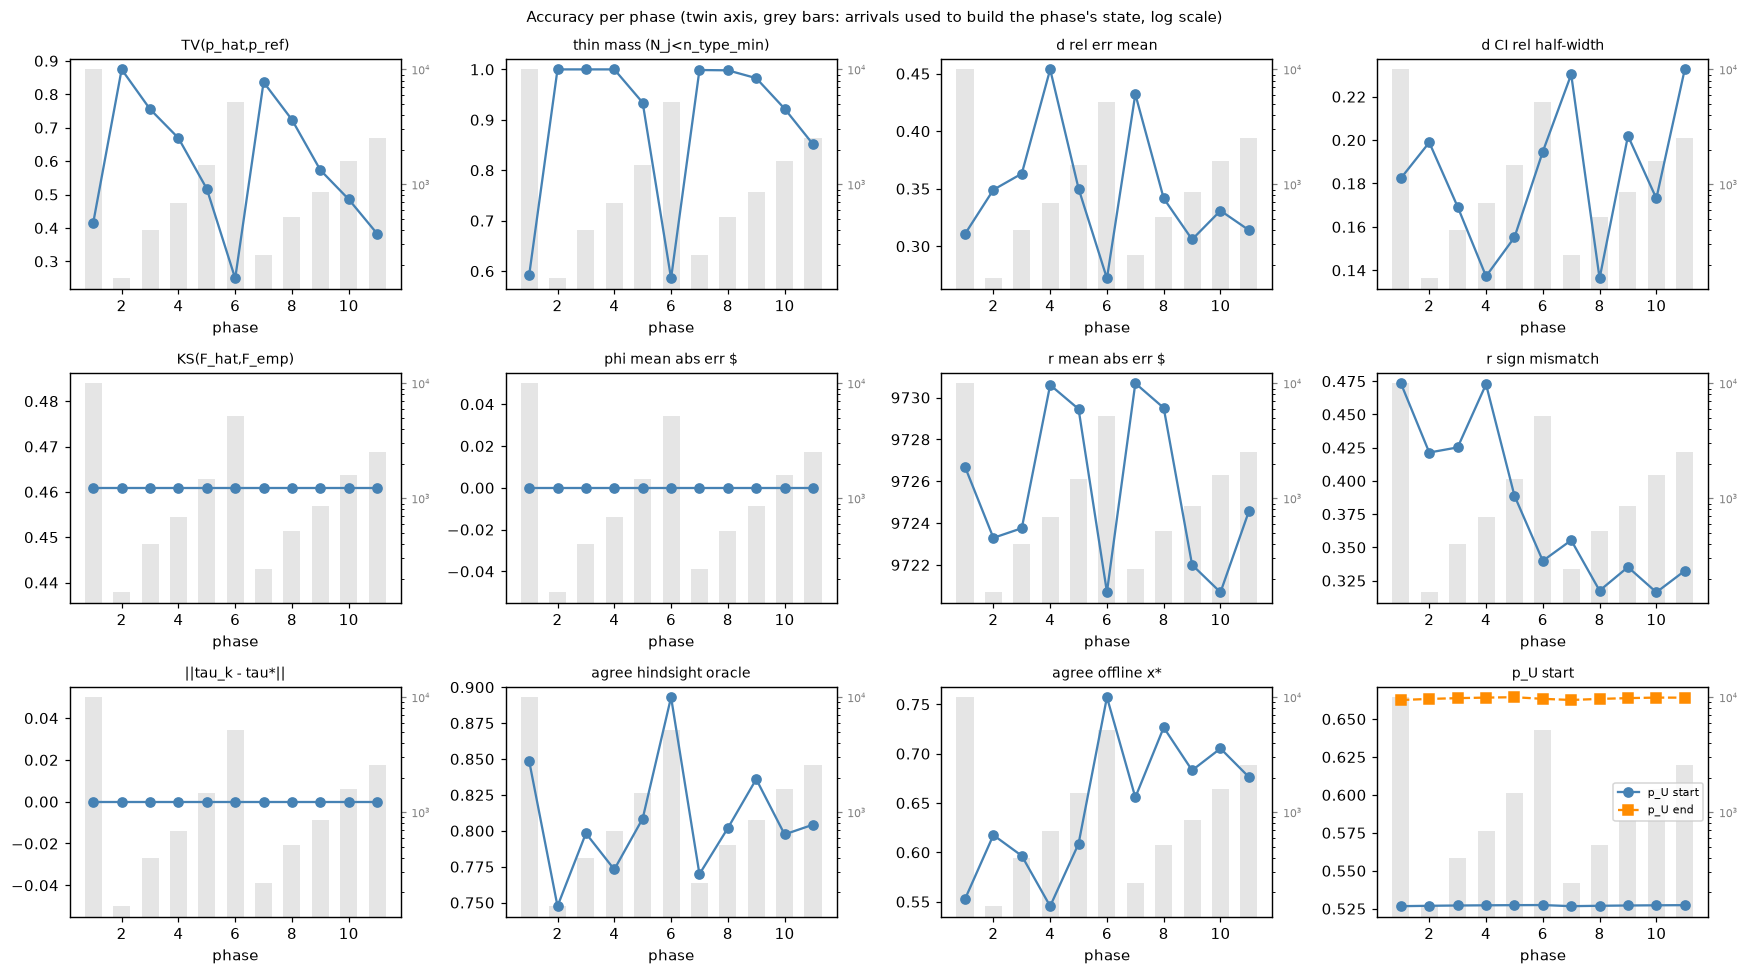

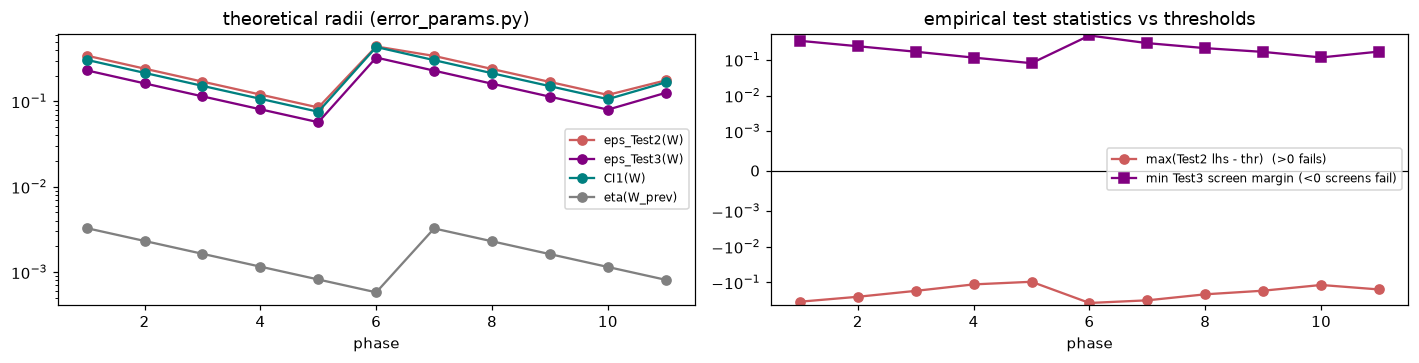

In [15]:
METRICS = ["TV(p_hat,p_ref)", "thin mass (N_j<n_type_min)", "d rel err mean", "d CI rel half-width",
           "KS(F_hat,F_emp)", "phi mean abs err $", "r mean abs err $", "r sign mismatch",
           "||tau_k - tau*||", "agree hindsight oracle", "agree offline x*", "p_U start"]
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, met in zip(axes.ravel(), METRICS):
    ax.plot(ACC0.index, ACC0[met], "o-", color="steelblue", label=met)
    ax.set_title(met, fontsize=9); ax.set_xlabel("phase")
    tw = ax.twinx()
    tw.bar(ACC0.index, ACC0["n used (arrivals)"], color="gray", alpha=0.2, width=0.6)
    tw.set_yscale("log"); tw.tick_params(labelsize=7, colors="gray")
    if met == "p_U start":
        ax.plot(ACC0.index, ACC0["p_U end"], "s--", color="darkorange", label="p_U end")
        ax.legend(fontsize=7)
    ax.set_zorder(tw.get_zorder() + 1); ax.patch.set_visible(False)
fig.suptitle("Accuracy per phase (twin axis, grey bars: arrivals used to build the phase's state, log scale)",
             fontsize=10)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for col, cc in (("eps_Test2(W)", "indianred"), ("eps_Test3(W)", "purple"), ("CI1(W)", "teal"),
                ("eta(W_prev)", "gray")):
    ax[0].plot(ACC0.index, ACC0[col], "o-", color=cc, label=col)
ax[0].set_yscale("log"); ax[0].legend(fontsize=8); ax[0].set_title("theoretical radii (error_params.py)")
ax[0].set_xlabel("phase")
ax[1].plot(ACC0.index, ACC0["max(Test2 lhs - thr)"], "o-", color="indianred", label="max(Test2 lhs - thr)  (>0 fails)")
ax[1].plot(ACC0.index, ACC0["min Test3 screen margin"], "s-", color="purple", label="min Test3 screen margin (<0 screens fail)")
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_yscale("symlog", linthresh=1e-3); ax[1].legend(fontsize=8)
ax[1].set_title("empirical test statistics vs thresholds"); ax[1].set_xlabel("phase")
plt.tight_layout(); plt.show()

In [16]:
def verdict(df, cols, lower_is_better=True):
    out = []
    for c in cols:
        x = df[c].to_numpy(float)
        d = np.diff(x) if lower_is_better else -np.diff(x)
        d2 = d[1:]
        out.append({"metric": c, "direction checked": "decrease" if lower_is_better else "increase",
                    "phase 1": x[0], "last phase": x[-1],
                    "monotone (all phases)": "yes" if np.all(d <= 1e-12) else "no",
                    "monotone (phases >= 2)": ("yes" if np.all(d2 <= 1e-12) else "no") if len(d2) else "n/a",
                    "last < first": "yes" if (x[-1] < x[0] if lower_is_better else x[-1] > x[0]) else "no"})
    return pd.DataFrame(out).set_index("metric")

V0 = pd.concat([
    verdict(ACC0, ["TV(p_hat,p_ref)", "thin mass (N_j<n_type_min)", "d rel err mean", "d rel err median",
                   "KS(F_hat,F_emp)", "phi mean abs err $", "r mean abs err $", "r rel err", "r sign mismatch",
                   "||tau_k - tau*||"]),
    verdict(ACC0, ["agree hindsight oracle", "agree offline x*"], lower_is_better=False),
])
display(V0.style.format(precision=4))
print(f"metrics monotone over all phases: {(V0['monotone (all phases)'] == 'yes').sum()} / {len(V0)};  "
      f"over phases >= 2: {(V0['monotone (phases >= 2)'] == 'yes').sum()} / {len(V0)};  "
      f"last better than phase 1: {(V0['last < first'] == 'yes').sum()} / {len(V0)}")

,direction checked,phase 1,last phase,monotone (all phases),monotone (phases >= 2),last < first
metric,,,,,,
"TV(p_hat,p_ref)",decrease,0.4159,0.3829,no,no,yes
thin mass (N_j<n_type_min),decrease,0.5917,0.8516,no,no,no
d rel err mean,decrease,0.3106,0.3140,no,no,no
d rel err median,decrease,0.1523,0.1481,no,no,yes
"KS(F_hat,F_emp)",decrease,0.4609,0.4609,yes,yes,no
phi mean abs err $,decrease,0.0000,0.0000,yes,yes,no
r mean abs err $,decrease,9726.6886,9724.5602,no,no,yes
r rel err,decrease,1.0002,1.0000,no,no,yes
r sign mismatch,decrease,0.4734,0.3324,no,no,yes


metrics monotone over all phases: 3 / 12;  over phases >= 2: 3 / 12;  last better than phase 1: 6 / 12


## Section 5: Baselines and regret (C.5, theoretical setting: true duration known at arrival)

* **DLENT-RT (online)**: the run above. R (logged) uses the phase's φ̂; R (yardstick) re-scores the same admitted
  set with φ_ref.
* **R_OPT fluid (existing benchmark code)**: λ̂_ref · T, the full-stream LP-RS (`summary["bench_global"]`). It is a
  per-tick fluid quantity on TYPE means, not a feasible schedule.
* **R_OPT offline job-level (ORACLE)**: MILP above (LP relaxation and no-capacity sum shown as upper bounds).
* **static τ* (full stream, ORACLE)**: (r_ref, τ*, v_ref) of the full stream, computed once; same event-driven
  loop, oracle and physical gate; no thinning, no learning, no restarts.
* **static Phase 0 (H)**: (r̃, τ, v) of Phase 0 (from H), never updated; no thinning.
* **static Phase 0 (H) + thinning at cap**: same, with U(t) ~ Bern((1 − ξ)/(1 + ε_D)), same random numbers as the
  online run (isolates the thinning effect from learning).

In [17]:
def baseline_table(run):
    model, a, opt = run["model"], run["A"], run["opt"]
    S = model.stream; R_ref = run["R_ref"]
    R_fluid = run["res"].summary["bench_global"]
    alg_adm = np.zeros(S.n, bool); alg_adm[a.loc[a["admit"], "i"].to_numpy()] = True
    algs = {"DLENT-RT (online)": dict(admit=alg_adm, R_own_total=float(a["R"].sum()),
                                      phys=np.isin(np.arange(S.n), a.loc[a["phys_reject"], "i"]))}
    for name, b in run["base"].items():
        algs[name] = dict(admit=b["admit"], R_own_total=float(b["R_own"][b["admit"]].sum()), phys=b["phys"])
    algs["offline job-level OPT (ORACLE)"] = dict(admit=opt["x"], R_own_total=np.nan, phys=np.zeros(S.n, bool))
    R_alg = float(R_ref[alg_adm].sum())
    rows = []
    for name, d in algs.items():
        adm = d["admit"]; Ry = float(R_ref[adm].sum())
        rows.append({"algorithm": name, "admitted": int(adm.sum()), "adm rate %": 100 * adm.mean(),
                     "phys rejects": int(d["phys"].sum()), "R own phi $": d["R_own_total"],
                     "R yardstick $": Ry, "adm with R_ref<0 %": 100 * (R_ref[adm] < 0).mean() if adm.any() else 0,
                     "R / R_OPT fluid": Ry / R_fluid, "R / R_OPT job": Ry / opt["R_ip"],
                     "R_ALG / R": R_alg / Ry if Ry else np.nan,
                     "regret vs fluid $": R_fluid - Ry, "regret vs job OPT $": opt["R_ip"] - Ry})
    df = pd.DataFrame(rows).set_index("algorithm")
    bounds = {"R_OPT fluid (bench_global)": R_fluid, "R_OPT job MILP": opt["R_ip"],
              "R_OPT job LP relaxation": opt["R_lp"], "sum of R_ref>0 (no capacity)": opt["R_nocap"],
              "R_ALG logged (summary R_total)": run["res"].summary["R_total"],
              "fluid regret (summary regret_global)": run["res"].summary["regret_global"],
              "per-phase fluid bench sum (summary)": run["res"].summary["bench_per_phase"]}
    return df, algs, bounds

BT0, ALGS0, BOUNDS0 = baseline_table(R0)
display(BT0.style.format(precision=4))
for k, v in BOUNDS0.items():
    print(f"{k:<40} {v:14,.3f} $")

,admitted,adm rate %,phys rejects,R own phi $,R yardstick $,adm with R_ref<0 %,R / R_OPT fluid,R / R_OPT job,R_ALG / R,regret vs fluid $,regret vs job OPT $
algorithm,,,,,,,,,,,
DLENT-RT (online),7405,48.3734,2,48391.6114,-157117.0710,29.1560,-1.0511,-0.8567,1.0000,306595.4905,340507.8841
"static tau* (full stream, ORACLE)",12612,82.3883,9,-227136.5166,-227136.5166,26.6809,-1.5195,-1.2385,0.6917,376614.9360,410527.3297
static Phase 0 (H),10226,66.8017,1,-610450.6553,-610450.6553,35.3217,-4.0839,-3.3287,0.2574,759929.0747,793841.4684
static Phase 0 (H) + thinning at cap,6793,44.3755,1,-398384.9656,-398384.9656,35.2716,-2.6652,-2.1723,0.3944,547863.3850,581775.7787
offline job-level OPT (ORACLE),10033,65.5409,0,nan,183390.8131,0.0000,1.2269,1.0000,-0.8567,-33912.3937,-0.0000


R_OPT fluid (bench_global)                  149,478.419 $
R_OPT job MILP                              183,390.813 $
R_OPT job LP relaxation                     183,447.317 $
sum of R_ref>0 (no capacity)                183,677.075 $
R_ALG logged (summary R_total)               48,391.611 $
fluid regret (summary regret_global)        101,086.808 $
per-phase fluid bench sum (summary)         153,144.294 $


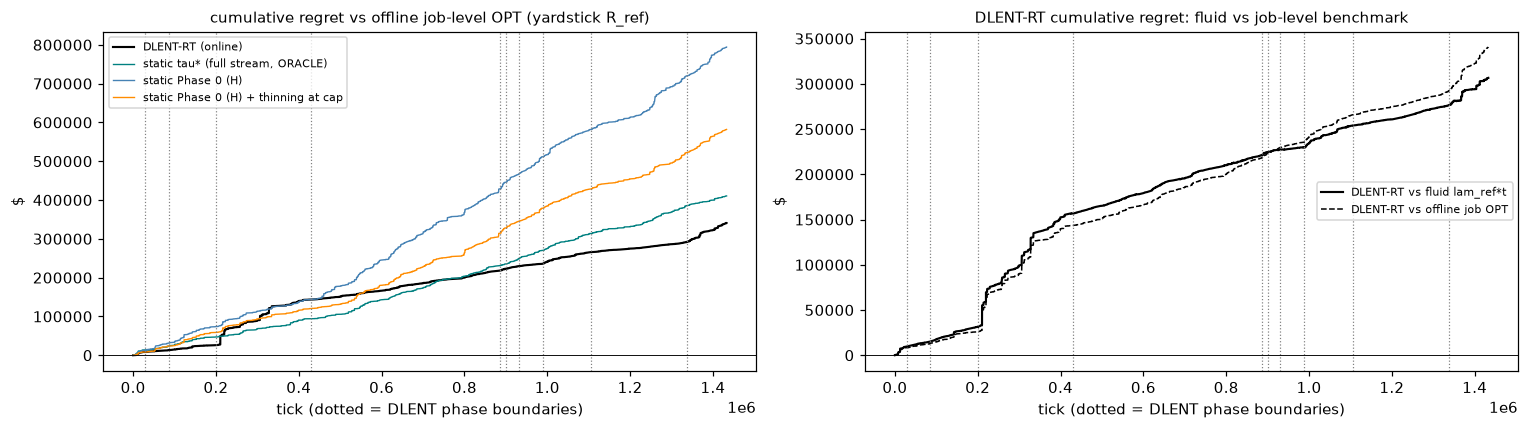

In [18]:
order = np.argsort(S0.tick)
tk = S0.tick[order]
Rr = R0["R_ref"][order]
lam_ref = R0["st_ref"].lam_star
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
cum_opt = np.cumsum(Rr * R0["opt"]["x"][order])
for (name, d), cc in zip(ALGS0.items(), ["k", "teal", "steelblue", "darkorange", "seagreen"]):
    if name.startswith("offline"):
        continue
    cum = np.cumsum(Rr * d["admit"][order])
    ax[0].plot(tk, cum_opt - cum, color=cc, lw=1.4 if name.startswith("DLENT") else 0.9, label=name)
    if name.startswith("DLENT"):
        ax[1].plot(tk, lam_ref * tk - cum, color="k", lw=1.4, label="DLENT-RT vs fluid lam_ref*t")
        ax[1].plot(tk, cum_opt - cum, color="k", ls="--", lw=1.0, label="DLENT-RT vs offline job OPT")
for a_ in ax:
    for b in PH0["tau_start"].iloc[1:]:
        a_.axvline(b, color="gray", ls=":", lw=0.8)
    a_.axhline(0, color="k", lw=0.6); a_.set_xlabel("tick (dotted = DLENT phase boundaries)"); a_.set_ylabel("$")
    a_.legend(fontsize=7)
ax[0].set_title("cumulative regret vs offline job-level OPT (yardstick R_ref)", fontsize=10)
ax[1].set_title("DLENT-RT cumulative regret: fluid vs job-level benchmark", fontsize=10)
plt.tight_layout(); plt.show()

In [19]:
def per_phase_regret(run, algs):
    a, ph = run["A"], run["ph"]
    R_ref, x = run["R_ref"], run["opt"]["x"]
    rows = []
    for _, p in ph.iterrows():
        m = int(p["m"]); ii = a.loc[a["m"] == m, "i"].to_numpy()
        opt_m = float(R_ref[ii][x[ii]].sum())
        row = {"phase": m, "R_OPT job (phase) $": opt_m,
               "DLENT fluid regret (code: bench_hindsight - R) $": float(p["regret_hindsight"])}
        for name, d in algs.items():
            if name.startswith("offline"):
                continue
            row[f"regret {name} $"] = opt_m - float(R_ref[ii][d["admit"][ii]].sum())
        rows.append(row)
    df = pd.DataFrame(rows).set_index("phase")
    df.loc["total"] = df.sum()
    return df

PR0 = per_phase_regret(R0, ALGS0)
display(PR0.style.format(precision=3))

,R_OPT job (phase) $,DLENT fluid regret (code: bench_hindsight - R) $,regret DLENT-RT (online) $,"regret static tau* (full stream, ORACLE) $",regret static Phase 0 (H) $,regret static Phase 0 (H) + thinning at cap $
phase,,,,,,
1,1676.746,1238.816,8345.890,13598.477,12613.175,8345.890
2,5357.920,3359.177,4984.638,10127.623,18708.002,15462.936
3,8367.611,4932.977,12740.462,23383.745,42409.121,34975.218
4,16061.826,9845.477,117340.026,46976.924,70044.520,61494.056
5,58046.289,34857.230,74830.170,137057.294,285159.472,194453.361
6,2874.586,1046.488,4907.939,4605.161,17444.412,13531.517
7,6919.626,4206.720,6435.589,12094.625,19699.919,16651.925
8,9874.254,4320.593,6023.346,22277.470,45342.291,33955.517
9,17978.725,8684.647,30178.100,43563.485,70391.316,49609.295


## Section 6: capacity_scale sweep

Same seeds, same stream, same BASE config; only c is multiplied before Phase 0. ξ_used is the forced
`constants.xi_override`; ξ_data, the thinning cap and the gate change with the scale (Section 0.1).

In [20]:
sweep = []
for s, run in RUNS.items():
    sm, ep, c = run["res"].summary, run["model"].ep, run["model"].c
    a = run["A"]
    bt, _, bd = baseline_table(run)
    mean, peak = occ_stats(run["te"], run["Ue"], 1, int(run["model"].ds.T))
    sweep.append({
        "capacity_scale": s, "c_cpu": c[0], "c_ram": c[1], "xi_data": run["ds"].xi, "xi_used": ep.xi,
        "p_U cap": run["p_cap"], "p_U min": a["p_U"].min(), "p_U mean": a["p_U"].mean(),
        "phys gate: jobs A>c": int(np.any(run["model"].stream.A > c, axis=1).sum()),
        "phases": sm["n_phases"], "end reasons": ", ".join(f"{k}:{v}" for k, v in sm["phase_end_reasons"].items() if v),
        "admitted": sm["n_admitted"], "adm rate %": 100 * sm["n_admitted"] / sm["n_arrivals"],
        "rej oracle": int((a["decision"] == "oracle reject").sum()),
        "rej thinning": int((a["decision"] == "thinning reject").sum()),
        "rej physical": int((a["decision"] == "physical reject").sum()),
        "occ cpu mean %": 100 * mean[0] / c[0], "occ ram mean %": 100 * mean[1] / c[1],
        "occ cpu peak %": 100 * peak[0] / c[0], "occ ram peak %": 100 * peak[1] / c[1],
        "R_ALG logged $": sm["R_total"], "R_ALG yardstick $": bt.loc["DLENT-RT (online)", "R yardstick $"],
        "R_OPT fluid $": bd["R_OPT fluid (bench_global)"], "R_OPT job $": bd["R_OPT job MILP"],
        "R_ALG/R_OPT fluid": bt.loc["DLENT-RT (online)", "R / R_OPT fluid"],
        "R_ALG/R_OPT job": bt.loc["DLENT-RT (online)", "R / R_OPT job"],
        "R_ALG/R_static tau*": bt.loc["static tau* (full stream, ORACLE)", "R_ALG / R"],
        "R_ALG/R_static P0": bt.loc["static Phase 0 (H)", "R_ALG / R"],
        "regret vs job OPT $": bt.loc["DLENT-RT (online)", "regret vs job OPT $"],
        "regret vs fluid $": bt.loc["DLENT-RT (online)", "regret vs fluid $"],
        "adm R_ref<0 % (ALG)": bt.loc["DLENT-RT (online)", "adm with R_ref<0 %"],
        "tau* (hindsight)": np.round(run["st_ref"].tau, 6),
    })
SWEEP = pd.DataFrame(sweep).set_index("capacity_scale")
display(SWEEP.T.style.format(precision=4))

capacity_scale,0.500000,1.000000,1.500000,2.000000,3.000000
c_cpu,1.9727,3.9455,5.9182,7.8909,11.8364
c_ram,1.2775,2.5551,3.8326,5.1102,7.6653
xi_data,1.0000,0.5000,0.3333,0.2500,0.1667
xi_used,0.0010,0.0010,0.0010,0.0010,0.0010
p_U cap,0.6650,0.6650,0.6650,0.6650,0.6650
p_U min,0.4360,0.5267,0.5659,0.5878,0.6115
p_U mean,0.6622,0.6636,0.6641,0.6643,0.6645
phys gate: jobs A>c,0,0,0,0,0
phases,11,11,11,11,11
end reasons,"test2:1, timeout:9, horizon:1","test2:1, timeout:9, horizon:1","test2:1, timeout:9, horizon:1","test2:1, timeout:9, horizon:1","test2:1, timeout:9, horizon:1"


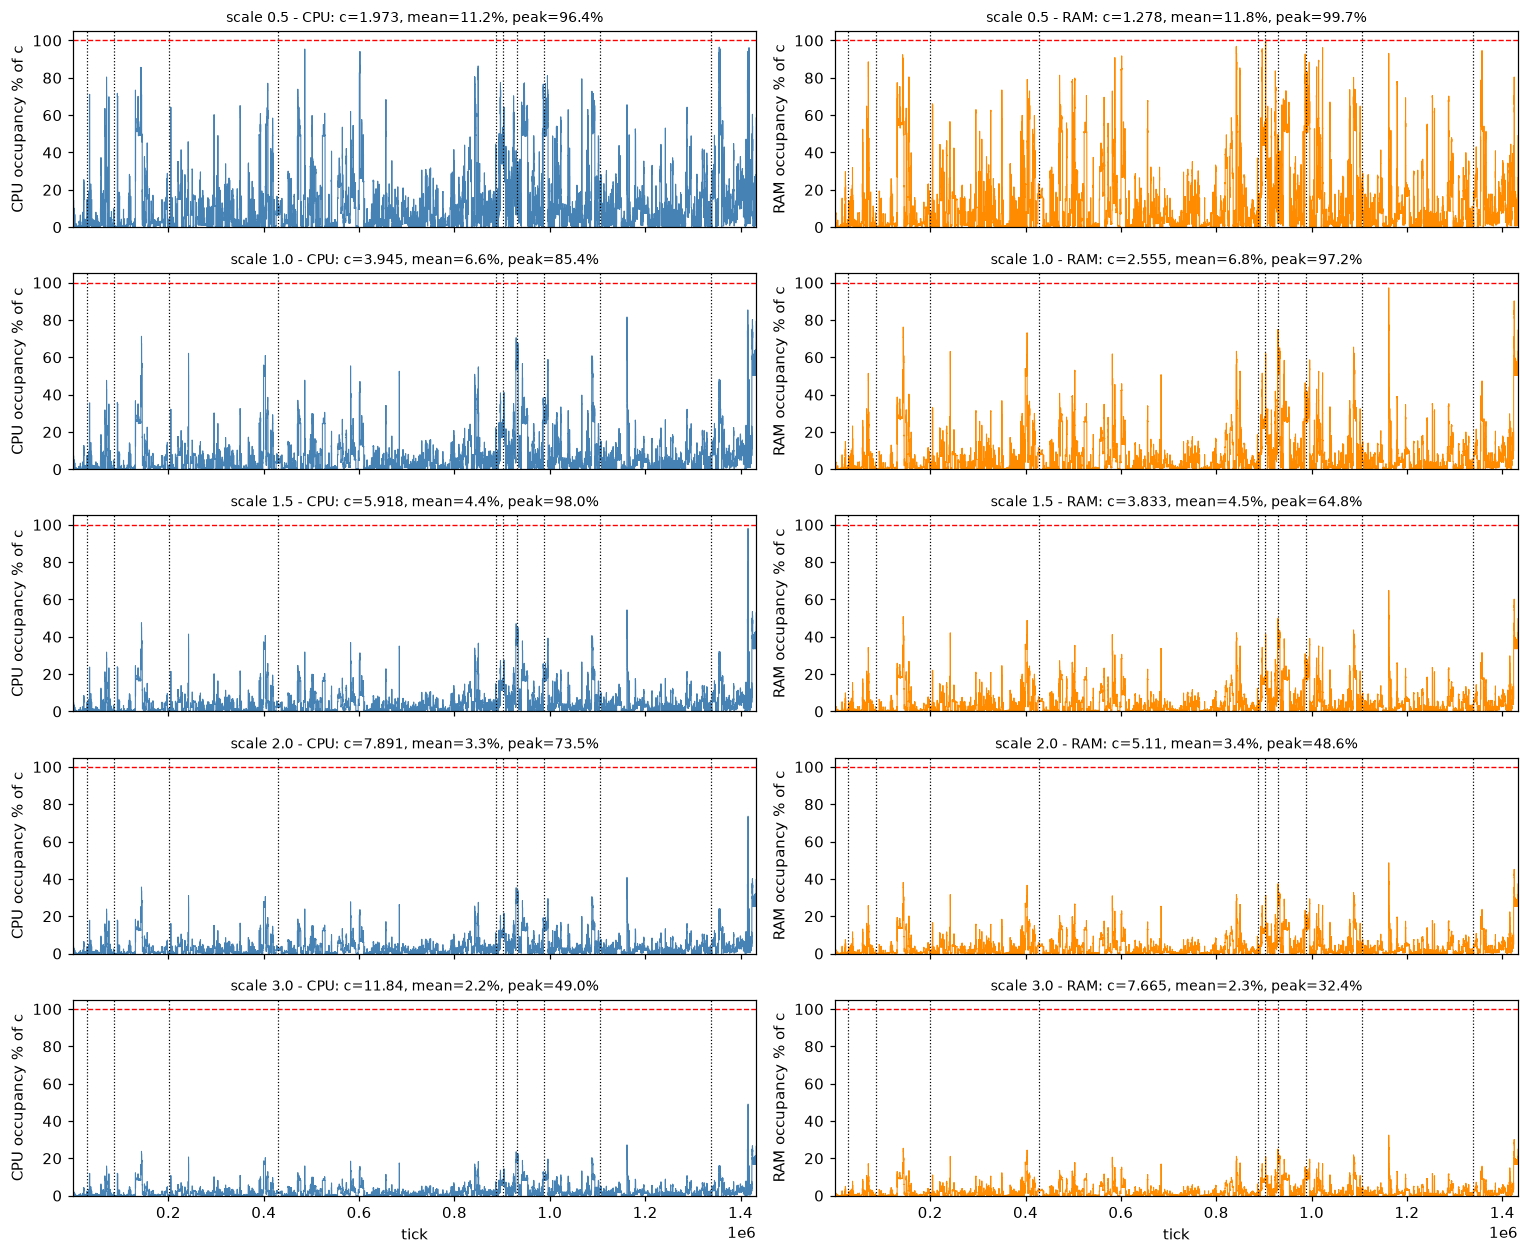

In [21]:
fig, axes = plt.subplots(len(RUNS), 2, figsize=(14, 2.3 * len(RUNS)), sharex=True, squeeze=False)
for (s, run), (a1, a2) in zip(RUNS.items(), axes):
    plot_occupancy(a1, a2, run, title=f"scale {s} - ")
for a_ in axes[-1]:
    a_.set_xlabel("tick")
plt.tight_layout(); plt.show()

## Section 7: Anomalies (numbers only)

In [22]:
an = []
# 1. |H| and s_C depend on data.n0 (notebook 01 overrides n0 = 10,000; default.yaml has 20,000)
for n0 in sorted({10_000, BASE.data.n0}):
    c_n = apply_overrides(BASE, {"data.n0": n0})
    ds_n = load_dataset(c_n); st_n = run_phase0(ds_n, c_n)
    an.append({"item": f"s_C with data.n0={n0:,}", "value": f"{st_n.carbon_price:.3f} $/kgCO2 "
               f"(|H|={ds_n.H.n:,}, |stream|={ds_n.stream.n:,}, K_q={st_n.norm_info['K_q']:.4g}, "
               f"D_q={st_n.norm_info['D_q']:.4g})"})
# 2. negative payments (payment = phi_tilde of the type's bin floor; lognormal: phi(L) can be < 0)
adm = A0[A0["admit"]]
negp = adm[adm["payment"] < 0]
an.append({"item": "admitted jobs with payment < 0",
           "value": f"{len(negp):,} / {len(adm):,} ({100 * len(negp) / max(len(adm), 1):.1f}%), sum = "
                    f"{negp['payment'].sum():,.2f} $; per phase {negp.groupby('m').size().to_dict()}; "
                    f"bins k {sorted(negp['k_bin'].unique().tolist())[:12]}{'...' if negp['k_bin'].nunique() > 12 else ''}"})
an.append({"item": "admitted jobs with payment > bid v", "value": f"{int((adm['payment'] > adm['v']).sum()):,}"})
for m, st in enumerate(M0.states, start=1):
    pp = st.p > 0
    an.append({"item": f"phase {m} state: populated types with phi_tilde < 0",
               "value": f"{int((st.phi_tilde[pp] < 0).sum())} / {int(pp.sum())} "
                        f"(p-mass {100 * st.p[pp][st.phi_tilde[pp] < 0].sum() / st.p[pp].sum():.1f}%)"})
# 3. jobs bigger than the cluster
big = np.any(S0.A > M0.c, axis=1)
an.append({"item": "xi_data = max a_max/c (scale 1)", "value": f"{R0['ds'].xi:.4f}  (forced xi_used = {M0.ep.xi})"})
an.append({"item": "stream jobs with A_i > c_i (never admissible)", "value": f"{int(big.sum()):,} ({100 * big.mean():.2f}%)"})
# 4. shadow prices and fluid LP load (only r~ > 0 types can enter the LP-RS optimum)
for m, st in enumerate(M0.states + [R0["st_ref"]], start=1):
    pos = st.r_tilde > 0
    load = (st.p[pos, None] * st.v[pos]).sum(0) / M0.c
    name = f"phase {m} state" if m <= len(M0.states) else "reference (full stream)"
    an.append({"item": f"{name}: tau, fluid load sum_(r~>0) p_j v_j / c",
               "value": f"tau={np.round(st.tau, 6)}, load={np.round(load, 4)}"})
pr = R0["st_ref"].p > 0
an.append({"item": "reference types: populated / stream jobs",
           "value": f"{int(pr.sum()):,} / {S0.n:,} ({S0.n / pr.sum():.2f} jobs per populated type)"})
# 5. tests and gamma
mx = max(abs(st.r_tilde[st.p > 0]).max() for st in M0.states)
an.append({"item": "max |r~| over populated types (all phase states)", "value": f"{mx:.3f} $ vs gamma_used = {M0.ep.gamma}"})
an.append({"item": "phase end reasons", "value": str(R0["res"].summary["phase_end_reasons"])})
an.append({"item": "max over phases of (Test2 lhs - thr)", "value": f"{ACC0['max(Test2 lhs - thr)'].max():.4g}"})
an.append({"item": "min over phases of Test3 screen margin", "value": f"{ACC0['min Test3 screen margin'].min():.4g}"})
# 6. reward bases
an.append({"item": "R_ALG logged (phase phi_hat) vs yardstick (phi_ref)",
           "value": f"{BT0.loc['DLENT-RT (online)', 'R own phi $']:,.2f} vs {BT0.loc['DLENT-RT (online)', 'R yardstick $']:,.2f} $"})
an.append({"item": "R_OPT fluid vs offline job-level MILP",
           "value": f"{BOUNDS0['R_OPT fluid (bench_global)']:,.2f} vs {BOUNDS0['R_OPT job MILP']:,.2f} $"})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(an).set_index("item"))

,value
item,
"s_C with data.n0=10,000","228.184 $/kgCO2 (|H|=10,000, |stream|=15,308, K_q=0.06984, D_q=15.94)"
admitted jobs with payment < 0,"1,204 / 7,405 (16.3%), sum = -10,911.85 $; per phase {1: 8, 2: 16, 3: 38, 4: 112, 5: 398, 6: 20, 7: 40, 8: 61, 9: 136, 10: 211, 11: 164}; bins k [6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]..."
admitted jobs with payment > bid v,0
phase 1 state: populated types with phi_tilde < 0,0 / 2673 (p-mass 0.0%)
phase 2 state: populated types with phi_tilde < 0,0 / 139 (p-mass 0.0%)
phase 3 state: populated types with phi_tilde < 0,0 / 350 (p-mass 0.0%)
phase 4 state: populated types with phi_tilde < 0,0 / 543 (p-mass 0.0%)
phase 5 state: populated types with phi_tilde < 0,0 / 934 (p-mass 0.0%)
phase 6 state: populated types with phi_tilde < 0,0 / 1773 (p-mass 0.0%)


## Export (week-29 report)

Writes figures (PNG, dpi 200) to `reports/week29/figures/` and tables (CSV) to `reports/week29/tables/`.
Figures are re-rendered by re-running the plotting cells above on the results already in memory, with
`plt.show` redirected to `savefig` (nothing is recomputed). Tables are the DataFrames built above; Tables 3, 7 and
the admitted-R<0 summary are arithmetic on those results.

In [23]:
import io, contextlib
REPORT_DIR = ROOT / "reports" / "week29"
FIG_DIR, TAB_DIR = REPORT_DIR / "figures", REPORT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "notebooks" / "src"))
from build import parse as _parse_src
_SRC = [c.source for c in _parse_src((ROOT / "notebooks" / "src" / "03_main_algorithm_analysis.py").read_text())
        if c.cell_type == "code"]

# (file stem, unique marker of the plotting cell, names for successive plt.show calls or None = numbered)
FIG_SPECS = [
    ("fig01_bids_phi", 'qhist(ax[0], A0["v"]', ["fig01_bids_phi"]),
    ("fig02_objectives_job_type", 'qhist(ax[0, 0], A0["SW"]', ["fig02_objectives_job_type"]),
    ("fig03_margin_phase", "N_PLOT = 800", None),
    ("fig04_occupancy", "plot_occupancy(ax[0], ax[1], R0", ["fig04_occupancy"]),
    ("fig05_phase_bars", "body = PT0.drop", ["fig05_phase_bars"]),
    ("fig06_accuracy", "METRICS = [", ["fig06_accuracy", "fig06b_theory_radii"]),
    ("fig07_cumulative_regret", "cum_opt = np.cumsum", ["fig07_cumulative_regret"]),
    ("fig08_occupancy_sweep", "zip(RUNS.items(), axes)", ["fig08_occupancy_sweep"]),
]
_real_show, _real_display = plt.show, display
saved_figs = []
for base, marker, names in FIG_SPECS:
    src = next(s for s in _SRC if marker in s and "FIG_SPECS" not in s)
    count = [0]
    def _save_show(*_a, _base=base, _names=names, _count=count, **_k):
        _count[0] += 1
        name = _names[_count[0] - 1] if _names else f"{_base}{_count[0]}"
        fig = plt.gcf()
        fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
        plt.close(fig)
        saved_figs.append(name)
    plt.show = _save_show
    globals()["display"] = lambda *_a, **_k: None
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            exec(src, globals())
    finally:
        plt.show = _real_show
        globals()["display"] = _real_display
plt.close("all")

def _csv(df, name, **kw):
    df.to_csv(TAB_DIR / f"{name}.csv", **kw)
    return name

ep0, sm0 = M0.ep, R0["res"].summary
setup = pd.Series({
    "trace": Path(BASE.data.batch_csv).name, "grid data": Path(BASE.data.grid_csv).name,
    "data.n0 (notebook override)": BASE.data.n0,
    "seed run (Phase-0 bids)": BASE.run.seed, "seed stream bids": BASE.run.seed + BASE.online.bid_seed_offset,
    "seed thinning": BASE.run.seed + BASE.online.thinning_seed_offset,
    "|H|": ds0.H.n, "|stream|": ds0.stream.n, "T (ticks)": ds0.T, "tick seconds": BASE.time.tick_seconds,
    "d_max (ticks)": ds0.d_max_steps, "c_cpu": ds0.capacity[0], "c_ram": ds0.capacity[1],
    "capacity mode": BASE.capacity.mode, "capacity fraction": BASE.capacity.fraction,
    "capacity concurrency_quantile": BASE.capacity.concurrency_quantile,
    "a_max_cpu": ds0.a_max[0], "a_max_ram": ds0.a_max[1], "xi_data": ds0.xi, "xi_used": ep0.xi,
    "gamma_used": ep0.gamma, "gamma_data": ep0.gamma_data, "delta": ep0.delta, "eps_D": ep0.eps_D,
    "thinning cap (1-xi)/(1+eps_D)": R0["p_cap"], "p_U min": A0["p_U"].min(), "p_U max": A0["p_U"].max(),
    "lambda1": L1, "lambda2": L2, "lambda3": L3, "lambda sum": L1 + L2 + L3,
    "s_C ($/kgCO2, frozen)": SC0, "normalization": BASE.normalization.strategy,
    "quantile q": BASE.normalization.quantile, "norm_ref": str(M0.state0.norm_ref),
    "bid strategy": BASE.bid.strategy, "bid sigma": BASE.bid.sigma, "u0": BASE.bid.base_utility_u0,
    "k_star": BASE.grid.k_star, "hw profiles": BASE.hardware.n_profiles, "model": BASE.model.kind,
    "n_type_min": BASE.phase_transition.n_type_min, "n_min": BASE.phase_transition.n_min,
}, name="value")

t3 = pd.DataFrame([{"phase": m, "tau_cpu": st.tau[0], "tau_ram": st.tau[1],
                    "arrivals": int((A0["m"] == m).sum()),
                    "points plotted": int(min(N_PLOT, (A0["m"] == m).sum())),
                    "subsampled": bool((A0["m"] == m).sum() > N_PLOT)}
                   for m, st in enumerate(M0.states, start=1)]).set_index("phase")

_neg = A0[A0["R_job"] < 0]
_na = _neg[_neg["admit"]]
adm_neg = pd.Series({
    "arrivals": len(A0), "R_job<0": len(_neg), "R_job<0 %": 100 * len(_neg) / len(A0),
    "R_nocarb<0 %": 100 * (A0["R_nocarb"] < 0).mean(),
    "admitted": int(A0["admit"].sum()), "admitted with R_job<0": len(_na),
    "admitted R_job<0 % of admitted": 100 * len(_na) / A0["admit"].sum(),
    "admitted R_job<0 % of negative jobs": 100 * len(_na) / max(len(_neg), 1),
    "of admitted R_job<0: score>0 %": 100 * (_na["score"] > 0).mean(),
    "of admitted R_job<0: Pi_job<0 %": 100 * (_na["PI"] < 0).mean(),
    "of admitted R_job<0: phi_mech<0 %": 100 * (_na["phi_mech"] < 0).mean(),
    "of admitted R_job<0: R_nocarb>=0 % (carbon flips sign)": 100 * (_na["R_nocarb"] >= 0).mean(),
    "of admitted R_job<0: mean r~_type $": _na["r_tilde"].mean(),
    "of admitted R_job<0: mean R_job $": _na["R_job"].mean(),
    "admitted with payment<0": int((A0.loc[A0["admit"], "payment"] < 0).sum()),
}, name="value")

_Ry = BT0["R yardstick $"]
_opt, _p0 = _Ry["offline job-level OPT (ORACLE)"], _Ry["static Phase 0 (H)"]
_p0t, _alg = _Ry["static Phase 0 (H) + thinning at cap"], _Ry["DLENT-RT (online)"]
_tot = _opt - _alg
t7 = pd.DataFrame([
    {"step": "OPT (job-level) -> static Phase 0", "attributed to": "discretization / type aggregation (Phase-0 types, no learning)", "$": _opt - _p0},
    {"step": "static Phase 0 -> + thinning at cap", "attributed to": "thinning", "$": _p0 - _p0t},
    {"step": "+ thinning at cap -> DLENT-RT online", "attributed to": "learning (ReInit) + early-phase thinning below the cap", "$": _p0t - _alg},
    {"step": "total regret (OPT - online)", "attributed to": "", "$": _tot},
]).set_index("step")
t7["% of total"] = 100 * t7["$"] / _tot
t7b = PR0.drop(index="total").copy()
t7b.insert(0, "arrivals", A0.groupby("m").size())
t7b["DLENT regret per arrival $"] = t7b["regret DLENT-RT (online) $"] / t7b["arrivals"]
t7b.loc["total"] = t7b.sum()
t7b.loc["total", "DLENT regret per arrival $"] = t7b.loc["total", "regret DLENT-RT (online) $"] / t7b.loc["total", "arrivals"]

t8 = SWEEP[["c_cpu", "c_ram", "xi_data", "phys gate: jobs A>c", "p_U min", "phases", "end reasons", "admitted",
            "adm rate %", "rej physical", "rej thinning", "occ cpu mean %", "occ ram mean %", "occ cpu peak %",
            "occ ram peak %", "R_ALG logged $", "R_ALG yardstick $", "R_OPT job $", "R_ALG/R_OPT job",
            "R_OPT fluid $", "R_ALG/R_OPT fluid", "tau* (hindsight)"]].copy()
t8["tau* (hindsight)"] = t8["tau* (hindsight)"].astype(str)

saved_tabs = [
    _csv(setup.to_frame(), "table00_setup"),
    _csv(const_df.T, "table00b_constants_per_scale"),
    _csv(pd.DataFrame(desc).set_index(["level", "objective"]), "table01_objective_quantiles"),
    _csv(pd.DataFrame(neg_rows).set_index(["level", "scope"]), "table02_negative_reward"),
    _csv(t3, "table03_phase_tau_points"),
    _csv(PT0, "table04_phase_results"),
    _csv(adm_neg.to_frame(), "table04b_admitted_negative"),
    _csv(ACC0, "table05_accuracy"),
    _csv(V0, "table05b_monotonicity"),
    _csv(BT0, "table06_baselines"),
    _csv(pd.Series(BOUNDS0, name="$").to_frame(), "table06b_benchmarks"),
    _csv(t7, "table07_regret_decomposition"),
    _csv(t7b, "table07b_regret_per_phase"),
    _csv(t8, "table08_capacity_sweep"),
    _csv(pd.DataFrame(an).set_index("item"), "table10_anomalies"),
]
print(f"figures -> {FIG_DIR}:")
print("  " + "\n  ".join(saved_figs))
print(f"tables -> {TAB_DIR}:")
print("  " + "\n  ".join(saved_tabs))

figures -> /Users/francescodangolo/Projects/dlent_rt/reports/week29/figures:
  fig01_bids_phi
  fig02_objectives_job_type
  fig03_margin_phase1
  fig03_margin_phase2
  fig03_margin_phase3
  fig03_margin_phase4
  fig03_margin_phase5
  fig03_margin_phase6
  fig03_margin_phase7
  fig03_margin_phase8
  fig03_margin_phase9
  fig03_margin_phase10
  fig03_margin_phase11
  fig04_occupancy
  fig05_phase_bars
  fig06_accuracy
  fig06b_theory_radii
  fig07_cumulative_regret
  fig08_occupancy_sweep
tables -> /Users/francescodangolo/Projects/dlent_rt/reports/week29/tables:
  table00_setup
  table00b_constants_per_scale
  table01_objective_quantiles
  table02_negative_reward
  table03_phase_tau_points
  table04_phase_results
  table04b_admitted_negative
  table05_accuracy
  table05b_monotonicity
  table06_baselines
  table06b_benchmarks
  table07_regret_decomposition
  table07b_regret_per_phase
  table08_capacity_sweep
  table10_anomalies
